# Evaluación e interpretación

In [1]:
from pathlib import Path
import warnings
import json
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import display

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "funciones"))
import Entrenamiento_red as mod

CARPETA_CURVAS = ROOT / "Curvas"
CARPETA_MODELOS = ROOT / "Resultados_Modelos1"
OUT = ROOT  
SEMILLAS = (1, 2, 3)
CABEZAS = ("lineal", "MLP", "KAN")
N_BOOTSTRAP = 1000
SEMILLA_BOOTSTRAP = 2026
VENTANAS_PICOS = {"Pico_1_MarJun": (13, 36), "Pico_2_SepDic": (49, 72)}

assert (ROOT / "funciones" / "Entrenamiento_red.py").is_file(), "Abre Jupyter en la raíz del proyecto."
assert CARPETA_CURVAS.is_dir() and CARPETA_MODELOS.is_dir()
assert N_BOOTSTRAP >= 1000
print("Carpeta del notebook/proyecto:", ROOT)
print("Los resultados se guardarán directamente en:", OUT)

Carpeta del notebook/proyecto: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos
Los resultados se guardarán directamente en: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos


## Evaluación final de los modelos seleccionados

Particiones temporales fijadas de antemano: entrenamiento **1981–1995**, validación **1996–2000**, prueba **2001–2003**. La semilla del modelo se fija usando únicamente validación. Las métricas finales y sus gráficas se calculan en prueba, comparando con el **satélite sin corregir**.

In [2]:
datos = mod.cargar_datos_red(CARPETA_CURVAS, escala='raiz')
meta = datos['meta'].copy().reset_index(drop=True)
ids = meta['curva'].astype(str).to_numpy()
part = meta['particion'].to_numpy()
TRAIN = part == "entrenamiento"
VALID = part == "validacion"
TEST = part == "prueba"

assert TRAIN.sum() > 0 and VALID.sum() > 0 and TEST.sum() > 0

assert meta.loc[TRAIN, "YEAR"].between(1981, 1995).all()
assert meta.loc[VALID, "YEAR"].between(1996, 2000).all()
assert meta.loc[TEST, "YEAR"].between(2001, 2003).all()
T = len(meta)
P = np.arange(1, 73)
cols_p = [f'P{k:02d}' for k in P]

def leer_pentadas(nombre):
    d = pd.read_csv(CARPETA_CURVAS / nombre, dtype={'curva': str})
    assert set(cols_p).issubset(d.columns), f'Faltan P01...P72 en {nombre}'
    assert not d['curva'].duplicated().any(), f'Curvas duplicadas en {nombre}'
    return d.set_index('curva').loc[ids, cols_p].to_numpy(float)

Y_crudo = leer_pentadas('curvas_estaciones_72_pentadas.csv')
S_crudo = leer_pentadas('curvas_satelite_72_pentadas.csv')
assert np.isfinite(Y_crudo).all() and np.isfinite(S_crudo).all()
print('Negativos en curvas originales suavizadas (estación/satélite):',
      int((Y_crudo < 0).sum()), int((S_crudo < 0).sum()))
Y = np.maximum(Y_crudo, 0.)
SAT = np.maximum(S_crudo, 0.)

est_tr = set(meta.loc[TRAIN, 'STATION_ID'].astype(str))
est_va = set(meta.loc[VALID, 'STATION_ID'].astype(str))
est_te = set(meta.loc[TEST, 'STATION_ID'].astype(str))
auditoria = pd.DataFrame({'conjunto':['Entrenamiento','Validación','Prueba'],
 'n_curvas':[TRAIN.sum(), VALID.sum(), TEST.sum()],
 'n_estaciones':[len(est_tr),len(est_va),len(est_te)]})
display(auditoria)
print('Intersecciones estaciones train/test:',len(est_tr & est_te),
      '| train/val:',len(est_tr & est_va), '| val/test:',len(est_va & est_te))
print('Años por grupo:',meta.groupby('particion')['YEAR'].agg(['min','max']).to_dict('index'))
if est_tr & est_te: warnings.warn('La prueba temporal incluye estaciones vistas en entrenamiento. NO declarar validación espacial independiente.')


Negativos en curvas originales suavizadas (estación/satélite): 1473 0


,conjunto,n_curvas,n_estaciones
0,Entrenamiento,1307,118
1,Validación,106,25
2,Prueba,60,24


Intersecciones estaciones train/test: 0 | train/val: 0 | val/test: 0
Años por grupo: {'entrenamiento': {'min': 1981, 'max': 1995}, 'prueba': {'min': 2001, 'max': 2003}, 'validacion': {'min': 1996, 'max': 2000}}


In [3]:
# Reconstruir predicciones en mm de TODOS los checkpoints, sin promediar semillas.
W_sat, R_sat = mod.matrices_integracion(datos['t'], datos['phi_sat'])
W_est, _ = mod.matrices_integracion(datos['t'], datos['phi_est'])
modelos, estados, predicciones, scores_pred = {}, {}, {}, {}
config_elegida = pd.read_csv(
    ROOT / "Tablas" / "08_red_configuracion_elegida.csv"
).set_index("cabeza")

for cabeza in CABEZAS:
    for semilla in SEMILLAS:
        ruta = CARPETA_MODELOS / f'red_{cabeza}_semilla{semilla:04d}.pt'
        if not ruta.is_file():
            print('Checkpoint no encontrado:',ruta.name)
            continue
        ck = torch.load(ruta,map_location='cpu',weights_only=False)  # solo checkpoints propios/confiables
        assert int(ck['q']) == int(config_elegida.loc[cabeza, 'q'])
        assert int(ck['M']) == int(config_elegida.loc[cabeza, 'M'])
        assert np.isclose(float(ck['lambda']),float(config_elegida.loc[cabeza, 'lambda']))
        escala = ck.get('escala','raiz')
        d = datos if escala=='raiz' else mod.cargar_datos_red(CARPETA_CURVAS, escala=escala)
        modelo = mod.crear_modelo(cabeza, W_sat, R_sat, int(ck['q']), int(ck['M']))
        modelo.load_state_dict(ck['estado'])
        modelo.eval()
        cov = (d['cov'] - ck['media_covariables']) / ck['desviacion_covariables']
        with torch.no_grad():
            s = modelo(torch.as_tensor(d['c_sat'],dtype=torch.float64),
                       torch.as_tensor(cov,dtype=torch.float64)).cpu().numpy()
        coef = ck['media_coeficientes'] + s @ ck['base_coeficientes']
        pred, recortes = mod.reconstruir_mm(coef,d['phi_est'][d['filas_pentadas']],escala)
        assert pred.shape == Y.shape and np.isfinite(pred).all() and np.min(pred)>=0
        nombre = f'{cabeza}_s{semilla}'
        modelos[nombre] = modelo; estados[nombre] = ck
        predicciones[nombre] = pred; scores_pred[nombre] = s
        print(f'{nombre:12s} q={ck["q"]}, M={ck["M"]}, '
              f'lambda={ck["lambda"]:g}, valores recortados={recortes:.2f}%')
assert predicciones, 'No se encontraron checkpoints: revisa Resultados_Modelos1/'

print('Modelos cargados:', len(predicciones))
display(pd.DataFrame([{'modelo':n,'min_pred_mm':float(p[TEST].min()),'max_pred_mm':float(p[TEST].max()),'media_pred_mm':float(p[TEST].mean())} for n,p in predicciones.items()]).round(3))


lineal_s1    q=8, M=5, lambda=1, valores recortados=0.00%
lineal_s2    q=8, M=5, lambda=1, valores recortados=0.00%
lineal_s3    q=8, M=5, lambda=1, valores recortados=0.00%
MLP_s1       q=8, M=5, lambda=10000, valores recortados=0.00%
MLP_s2       q=8, M=5, lambda=10000, valores recortados=0.01%
MLP_s3       q=8, M=5, lambda=10000, valores recortados=0.02%
KAN_s1       q=8, M=5, lambda=100, valores recortados=0.00%
KAN_s2       q=8, M=5, lambda=100, valores recortados=0.00%
KAN_s3       q=8, M=5, lambda=100, valores recortados=0.00%
Modelos cargados: 9


,modelo,min_pred_mm,max_pred_mm,media_pred_mm
0,lineal_s1,0.266,69.884,22.089
1,lineal_s2,0.526,61.858,21.034
2,lineal_s3,0.114,66.775,21.045
3,MLP_s1,1.388,64.211,21.387
4,MLP_s2,1.193,66.514,22.772
5,MLP_s3,0.240,68.808,22.293
6,KAN_s1,1.798,106.842,20.732
7,KAN_s2,2.740,62.325,19.767
8,KAN_s3,1.411,84.957,20.003


In [4]:
# Selección de la semilla con validación solamente, antes de mirar métricas en prueba.
def recm_validacion(pred):
    delta = pred[VALID] - Y[VALID]
    return float(np.mean(np.sqrt(np.mean(delta**2, axis=1))))

REFS = {}
for cabeza in CABEZAS:
    candidatos = [nombre for nombre in predicciones if nombre.startswith(cabeza + '_')]
    if candidatos:
        REFS[cabeza] = min(candidatos, key=lambda nombre: recm_validacion(predicciones[nombre]))
assert 'KAN' in REFS, 'Falta al menos un checkpoint KAN.'
KAN_REF = REFS['KAN']
print('Modelos fijados por validación:', REFS)

Modelos fijados por validación: {'lineal': 'lineal_s1', 'MLP': 'MLP_s2', 'KAN': 'KAN_s3'}


In [5]:
# Referencias de la evaluación: curva suavizada de la estación (Y) y del satélite sin corregir (SAT), recortadas en 0
EVAL = TEST
print('Prueba:', int(TEST.sum()), 'curvas')

Prueba: 60 curvas


## Las cuatro métricas obligatorias en prueba

Comparación de la KAN, los modelos de referencia y el satélite sin corregir frente a la **curva suavizada de la estación** (recortada en 0): **L² relativo**, **KGE 2009**, **sesgo del acumulado anual (%)** y **error de fecha de ambos picos**. Como métrica auxiliar se conserva RECM. Se usan todas las curvas de prueba. Las ventanas de pico son las definidas previamente y las fechas se representan mediante péntadas de cinco días.

In [6]:
def metricas_por_curva(obs, pred):
    obs = np.asarray(obs, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert obs.shape == pred.shape and obs.ndim == 2 and obs.shape[1] == 72
    assert np.isfinite(obs).all() and np.isfinite(pred).all()
    err = pred - obs
    norma_error = np.sqrt(np.trapezoid(err**2, x=P, axis=1))
    norma_obs = np.sqrt(np.trapezoid(obs**2, x=P, axis=1))
    l2_rel = norma_error / np.where(norma_obs > 1e-12, norma_obs, np.nan)
    rmse = np.sqrt(np.mean(err**2, axis=1))
    om, pm = obs.mean(axis=1), pred.mean(axis=1)
    os, ps = obs.std(axis=1), pred.std(axis=1)
    r = np.mean((obs-om[:,None])*(pred-pm[:,None]), axis=1) / np.where(os*ps > 1e-12, os*ps, np.nan)
    alpha = ps / np.where(os > 1e-12, os, np.nan)
    beta = pm / np.where(np.abs(om) > 1e-12, om, np.nan)
    kge = 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)
    acum_obs, acum_pred = obs.sum(axis=1), pred.sum(axis=1)
    sesgo = 100*(acum_pred-acum_obs)/np.where(acum_obs > 1e-12, acum_obs, np.nan)
    tabla = pd.DataFrame({'L2_relativo':l2_rel, 'RECM_mm':rmse, 'KGE':kge,
                         'sesgo_anual_pct':sesgo, 'acum_obs_mm':acum_obs, 'acum_pred_mm':acum_pred})
    for etiqueta, (inicio, fin) in VENTANAS_PICOS.items():
        sl = slice(inicio-1, fin)
        po = np.argmax(obs[:, sl], axis=1) + inicio
        pp = np.argmax(pred[:, sl], axis=1) + inicio
        tabla[f'error_{etiqueta}_dias'] = np.abs(pp-po)*5
        tabla[f'pico_obs_{etiqueta}'] = po
        tabla[f'pico_pred_{etiqueta}'] = pp
    tabla['error_dos_picos_dias'] = tabla[[f'error_{k}_dias' for k in VENTANAS_PICOS]].mean(axis=1)
    return tabla

metricas = {}

for nombre, pred in [('Satelite', SAT), *[(nombre, predicciones[nombre]) for nombre in REFS.values()]]:
    tabla = metricas_por_curva(Y[EVAL], pred[EVAL])
    tabla.insert(0, 'modelo', nombre)
    tabla.insert(1, 'curva', ids[EVAL])
    tabla.insert(2, 'particion', part[EVAL])
    tabla.insert(3, 'STATION_ID', meta.loc[EVAL,'STATION_ID'].astype(str).to_numpy())
    tabla.insert(4, 'YEAR', meta.loc[EVAL,'YEAR'].to_numpy())
    metricas[nombre] = tabla
metricas_curva = pd.concat(metricas.values(), ignore_index=True)
campos = ['L2_relativo','RECM_mm','KGE','sesgo_anual_pct',
          'error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias','error_dos_picos_dias']
resumen = metricas_curva.groupby('modelo')[campos].mean().round(4)
display(resumen)


,L2_relativo,RECM_mm,KGE,sesgo_anual_pct,error_Pico_1_MarJun_dias,error_Pico_2_SepDic_dias,error_dos_picos_dias
modelo,,,,,,,
KAN_s3,0.3808,8.9379,0.5128,3.2604,17.9167,9.5833,13.7500
MLP_s2,0.3932,8.4867,0.5602,19.9545,15.2500,7.2500,11.2500
Satelite,0.5003,10.5866,0.4407,31.2890,15.4167,19.2500,17.3333
lineal_s1,0.4100,8.9565,0.5175,14.9843,16.0000,6.9167,11.4583


## IC bootstrap del 95 % por estaciones

Se remuestrean **estaciones completas** (no péntadas individuales) con reemplazo, conservando juntos los años de una misma estación. Se calculan ≥1000 réplicas, IC percentiles del 95 % y diferencias pareadas frente al satélite sin corregir. Los IC condicionan en los checkpoints fijados: no incluyen incertidumbre por reentrenamiento.

,modelo,metrica,n_validos,estimacion,ic95_inf,ic95_sup,diferencia_vs_satelite,dif_ic95_inf,dif_ic95_sup
0,Satelite,L2_relativo,60,0.5003,0.3935,0.6275,0.0000,0.0000,0.0000
2,Satelite,KGE,60,0.4407,0.2930,0.5655,0.0000,0.0000,0.0000
3,Satelite,sesgo_anual_pct,60,31.2890,13.1192,51.1004,0.0000,0.0000,0.0000
6,Satelite,error_dos_picos_dias,60,17.3333,14.9537,19.6053,0.0000,0.0000,0.0000
7,lineal_s1,L2_relativo,60,0.4100,0.3602,0.4725,-0.0904,-0.1630,-0.0289
9,lineal_s1,KGE,60,0.5175,0.4449,0.5747,0.0767,-0.0007,0.1633
10,lineal_s1,sesgo_anual_pct,60,14.9843,2.9808,28.8716,-16.3048,-24.5928,-9.3405
13,lineal_s1,error_dos_picos_dias,60,11.4583,9.8770,12.9920,-5.8750,-7.4562,-4.1097
14,MLP_s2,L2_relativo,60,0.3932,0.3361,0.4674,-0.1071,-0.1680,-0.0522
16,MLP_s2,KGE,60,0.5602,0.4680,0.6362,0.1194,0.0474,0.1981


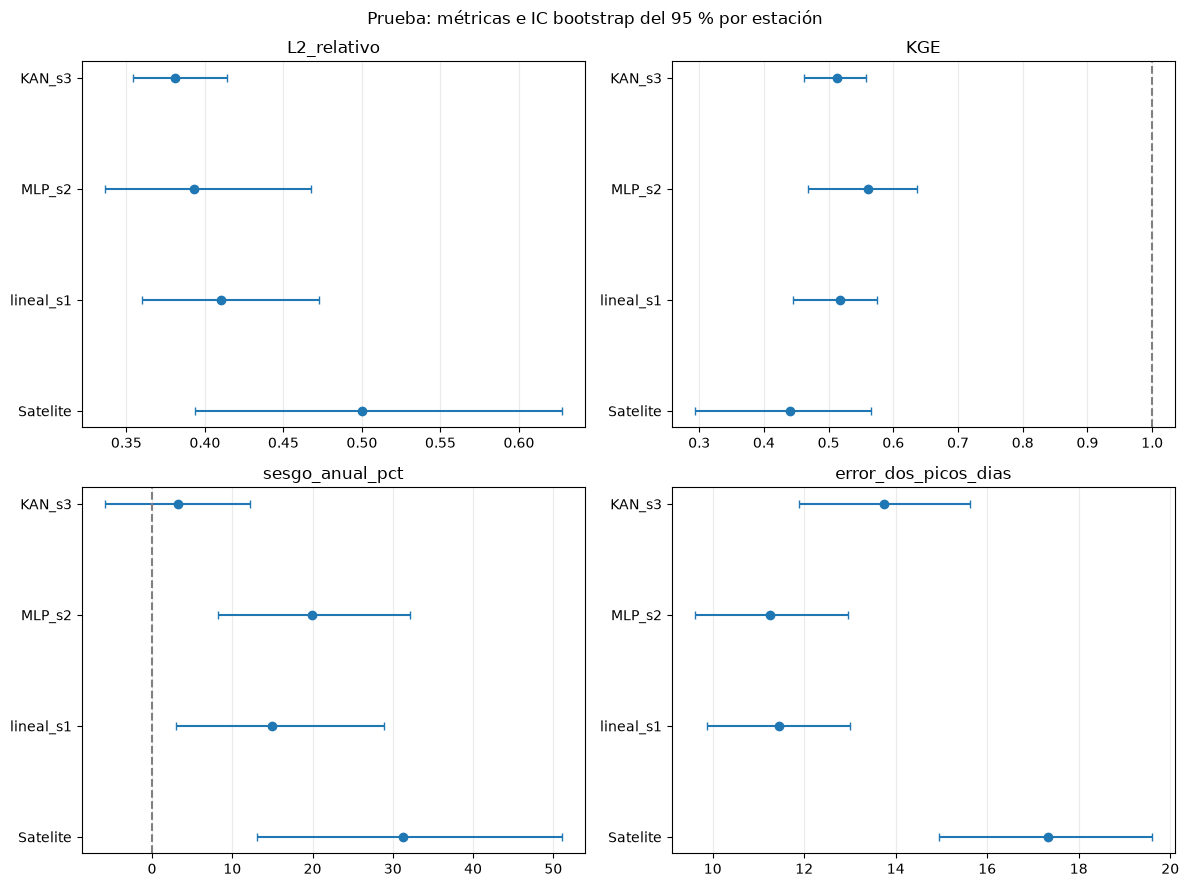

In [7]:
rng = np.random.default_rng(SEMILLA_BOOTSTRAP)
grupos = meta.loc[EVAL, 'STATION_ID'].astype(str).to_numpy()
estaciones = np.unique(grupos)
indices_por_est = {e:np.flatnonzero(grupos == e) for e in estaciones}
replicas = []
for b in range(N_BOOTSTRAP):
    muestra = rng.choice(estaciones, len(estaciones), replace=True)
    replicas.append(np.concatenate([indices_por_est[e] for e in muestra]))
assert len(replicas) >= 1000 and all(ix.max() < EVAL.sum() for ix in replicas)

met_test = {n:t[campos].reset_index(drop=True) for n,t in metricas.items()}
registros = []
for nombre, t in met_test.items():
    for campo in campos:
        vals = t[campo].to_numpy(float)
        base = met_test['Satelite'][campo].to_numpy(float)
        boot = np.array([np.nanmean(vals[ix]) for ix in replicas])
        dif = np.array([np.nanmean(vals[ix]-base[ix]) for ix in replicas])
        registros.append({'modelo':nombre, 'metrica':campo, 'n_validos':int(np.isfinite(vals).sum()),
                          'estimacion':np.nanmean(vals), 'ic95_inf':np.nanquantile(boot,.025),
                          'ic95_sup':np.nanquantile(boot,.975),
                          'diferencia_vs_satelite':np.nanmean(vals-base),
                          'dif_ic95_inf':np.nanquantile(dif,.025), 'dif_ic95_sup':np.nanquantile(dif,.975)})
boot_res = pd.DataFrame(registros)
display(boot_res[boot_res.metrica.isin(['L2_relativo','KGE','sesgo_anual_pct','error_dos_picos_dias'])].round(4))
fig, axs = plt.subplots(2,2,figsize=(12,9))
for ax,campo in zip(axs.flat,['L2_relativo','KGE','sesgo_anual_pct','error_dos_picos_dias']):
    sub = boot_res[boot_res.metrica.eq(campo)].reset_index(drop=True)
    yy = np.arange(len(sub))
    ax.errorbar(sub.estimacion,yy,
                xerr=[sub.estimacion-sub.ic95_inf,sub.ic95_sup-sub.estimacion],fmt='o',capsize=3)
    ax.set_yticks(yy,sub.modelo)
    ax.set_title(campo)
    ax.grid(axis='x',alpha=.25)
    if campo == 'sesgo_anual_pct':ax.axvline(0,color='gray',ls='--')
    if campo == 'KGE':ax.axvline(1,color='gray',ls='--')
fig.suptitle('Prueba: métricas e IC bootstrap del 95 % por estación')
fig.tight_layout();plt.show()

## Wilcoxon pareada por estación

La unidad de comparación es la estación. Para estaciones con varios años se promedia la métrica por estación y se compara la KAN **seleccionada por validación** contra el satélite sin corregir. Para el sesgo se compara su **magnitud absoluta**. Se reportan valores p bilaterales, medianas de diferencias y corrección de Holm para los cinco contrastes.

In [8]:
tabla_kan = metricas[KAN_REF].copy()
tabla_sat = metricas['Satelite'].copy()
columnas_w = ['L2_relativo','KGE','sesgo_anual_pct',
              'error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias']
resultados_w = []
for campo in columnas_w:
    if campo == 'sesgo_anual_pct':
        a = tabla_kan.assign(magnitud=tabla_kan[campo].abs()).groupby('STATION_ID')['magnitud'].mean()
        b = tabla_sat.assign(magnitud=tabla_sat[campo].abs()).groupby('STATION_ID')['magnitud'].mean()
    else:
        a = tabla_kan.groupby('STATION_ID')[campo].mean()
        b = tabla_sat.groupby('STATION_ID')[campo].mean()
    pares = pd.concat([a.rename('KAN'),b.rename('Satelite')],axis=1,join='inner').dropna()
    diferencia = pares['KAN']-pares['Satelite']
    if len(pares) < 2 or np.allclose(diferencia.to_numpy(), 0):
        W, pvalor = np.nan, np.nan
    else:
        prueba = wilcoxon(pares['KAN'],pares['Satelite'],alternative='two-sided',zero_method='wilcox')
        W, pvalor = float(prueba.statistic), float(prueba.pvalue)
    resultados_w.append({'metrica':campo,'n_estaciones':len(pares),
                         'mediana_diferencia_KAN_menos_satelite':float(diferencia.median()),
                         'W':W,'p_valor':pvalor})
wilcoxon_df = pd.DataFrame(resultados_w)
# Ajuste Holm sin depender de librerías adicionales.
p = wilcoxon_df['p_valor'].to_numpy(float)
p_aj = np.full_like(p,np.nan)
validos = np.flatnonzero(np.isfinite(p))
orden = validos[np.argsort(p[validos])]
max_prev = 0.0
for k,idx in enumerate(orden):
    max_prev = max(max_prev, min(1.0,(len(orden)-k)*p[idx]))
    p_aj[idx] = max_prev
wilcoxon_df['p_holm'] = p_aj
display(wilcoxon_df.round(5))


,metrica,n_estaciones,mediana_diferencia_KAN_menos_satelite,W,p_valor,p_holm
0,L2_relativo,24,-0.02866,89.0,0.08392,0.16784
1,KGE,24,0.00165,127.0,0.52706,0.52706
2,sesgo_anual_pct,24,-6.46272,82.0,0.05264,0.15792
3,error_Pico_1_MarJun_dias,24,1.66667,18.0,0.00543,0.02170
4,error_Pico_2_SepDic_dias,24,-10.00000,9.5,0.00009,0.00046


## Curva de la estación, satélite sin corregir y KAN en prueba

Se presentan los casos de mayor mejora, mayor deterioro, máxima precipitación y comportamiento intermedio, y se grafica el error medio por péntada. 

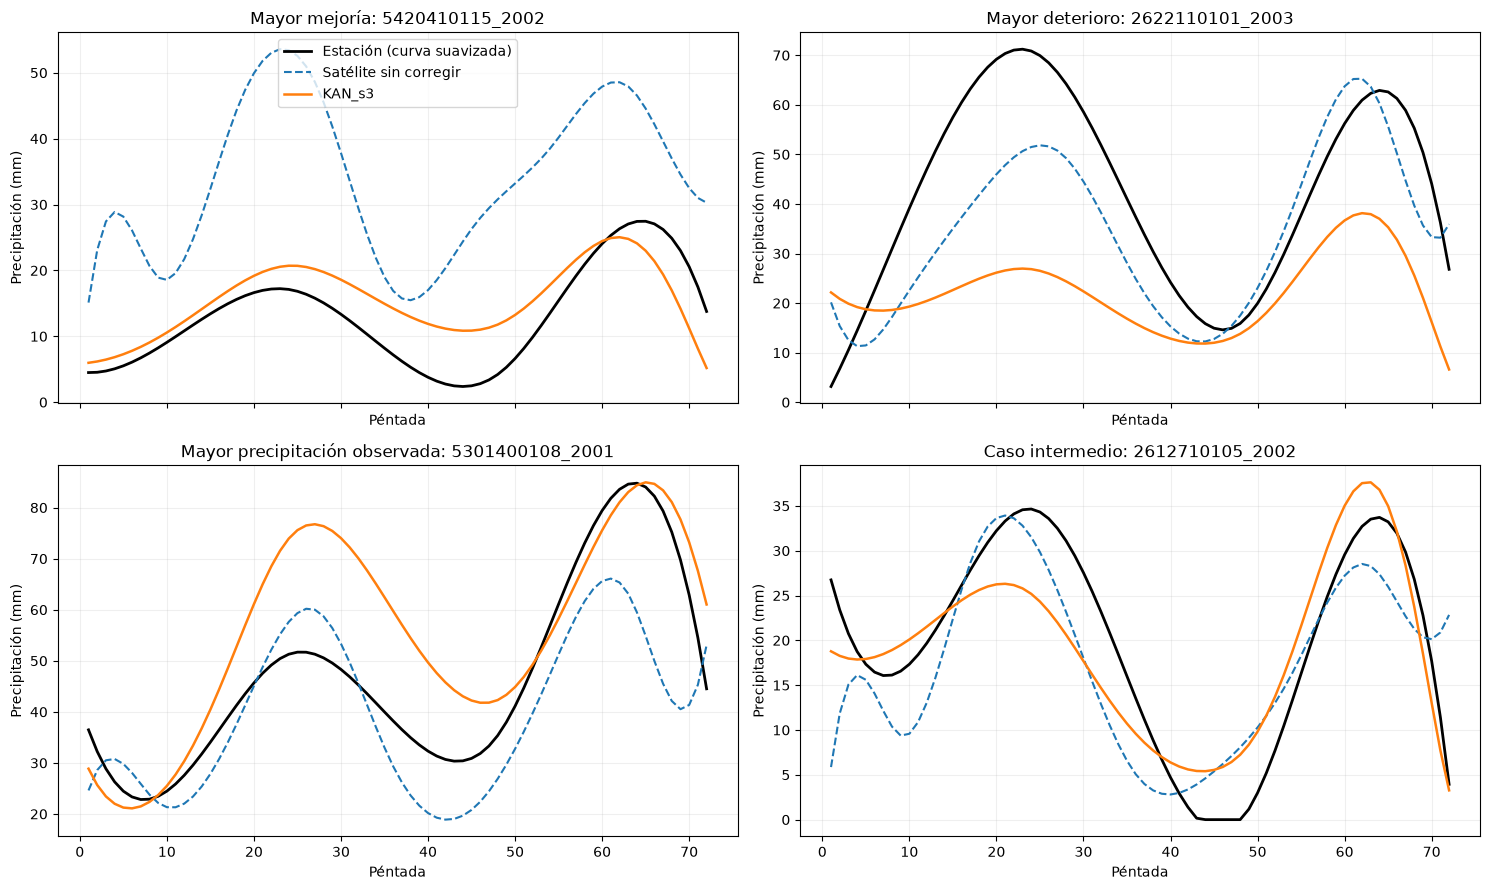

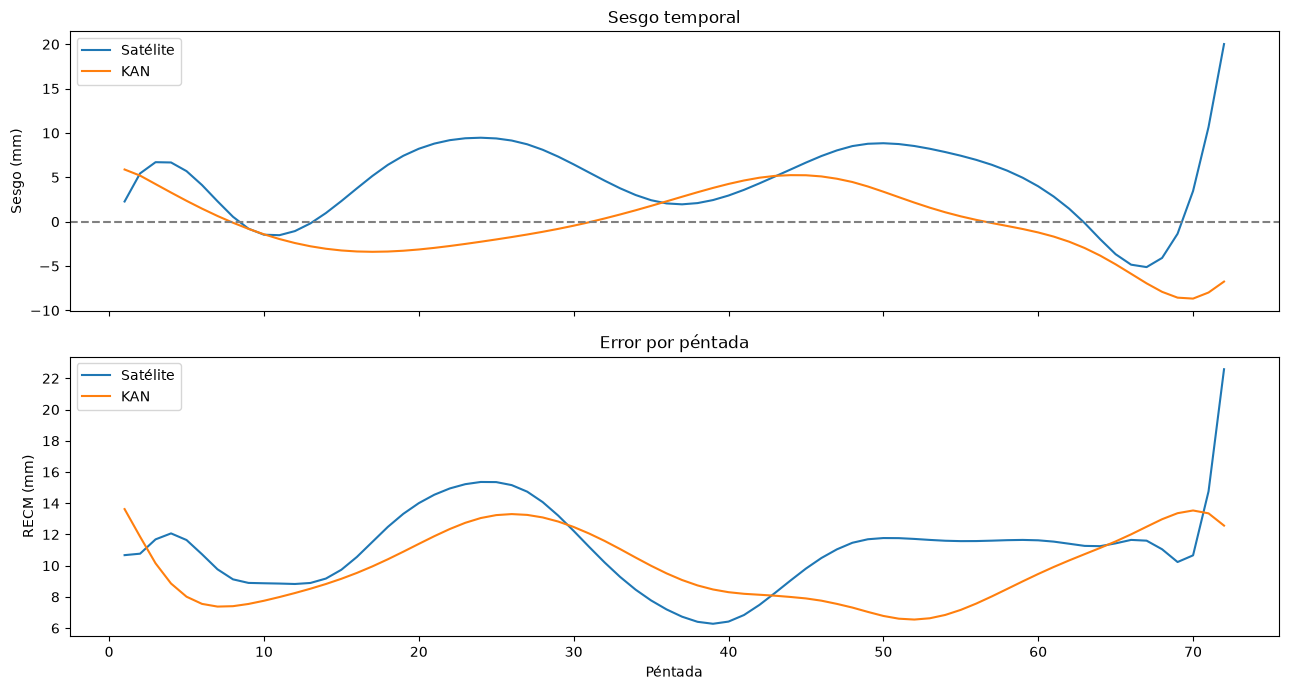

In [9]:
indices = np.flatnonzero(EVAL)
obs_test = Y[EVAL]
sat_test = SAT[EVAL]
kan_test = predicciones[KAN_REF][EVAL]
met_kan = metricas_por_curva(obs_test,kan_test)
met_sat = metricas_por_curva(obs_test,sat_test)
mejora = met_sat['L2_relativo'].to_numpy() - met_kan['L2_relativo'].to_numpy()
pos = [int(np.argmax(mejora)), int(np.argmin(mejora)),
       int(np.argmax(obs_test.sum(axis=1))), int(np.argmin(np.abs(mejora-np.median(mejora))))]
casos = indices[pos]
etiquetas = ['Mayor mejoría','Mayor deterioro','Mayor precipitación observada','Caso intermedio']
fig,axs = plt.subplots(2,2,figsize=(15,9),sharex=True)
for ax,i,etiqueta in zip(axs.flat,casos,etiquetas):
    ax.plot(P,Y[i],label='Estación (curva suavizada)',color='black',linewidth=2)
    ax.plot(P,SAT[i],label='Satélite sin corregir',linestyle='--')
    ax.plot(P,predicciones[KAN_REF][i],label=KAN_REF,linewidth=1.8)
    ax.set_title(f'{etiqueta}: {ids[i]}')
    ax.set(xlabel='Péntada',ylabel='Precipitación (mm)');ax.grid(alpha=.2)
axs[0,0].legend();fig.tight_layout()
plt.show()

fig,axs=plt.subplots(2,1,figsize=(13,7),sharex=True)
for nombre,pred in [('Satélite',SAT),('KAN',predicciones[KAN_REF])]:
    error=pred[EVAL]-Y[EVAL]
    axs[0].plot(P,error.mean(axis=0),label=nombre)
    axs[1].plot(P,np.sqrt(np.mean(error**2,axis=0)),label=nombre)
axs[0].axhline(0,color='gray',ls='--');axs[0].set(ylabel='Sesgo (mm)',title='Sesgo temporal')
axs[1].set(ylabel='RECM (mm)',xlabel='Péntada',title='Error por péntada')
axs[0].legend();axs[1].legend();fig.tight_layout()
plt.show()

## Resultados según fase ENSO

Las fases se toman de `data/enso_evaluacion.csv`, clasificado con el ONI mensual por ventanas trimestrales móviles. **Fuente del índice ONI:** NOAA Climate Prediction Center (CPC), https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ONI_v5.php. El RECM por fase se calcula sobre el tramo temporal de cada fase.

Columnas ENSO: ['YEAR', 'mes_central', 'ventana', 'ONI', 'fase_enso']


,modelo,fase,n_segmentos,n_pentadas,RECM_medio,sesgo_pct_medio
0,KAN_s3,El Niño,39,1068,9.359,41.411
1,KAN_s3,La Niña,21,252,7.176,-11.048
2,KAN_s3,Neutral,60,3000,8.700,6.168
3,Satelite,El Niño,39,1068,9.118,41.117
4,Satelite,La Niña,21,252,8.372,23.936
5,Satelite,Neutral,60,3000,11.134,39.482


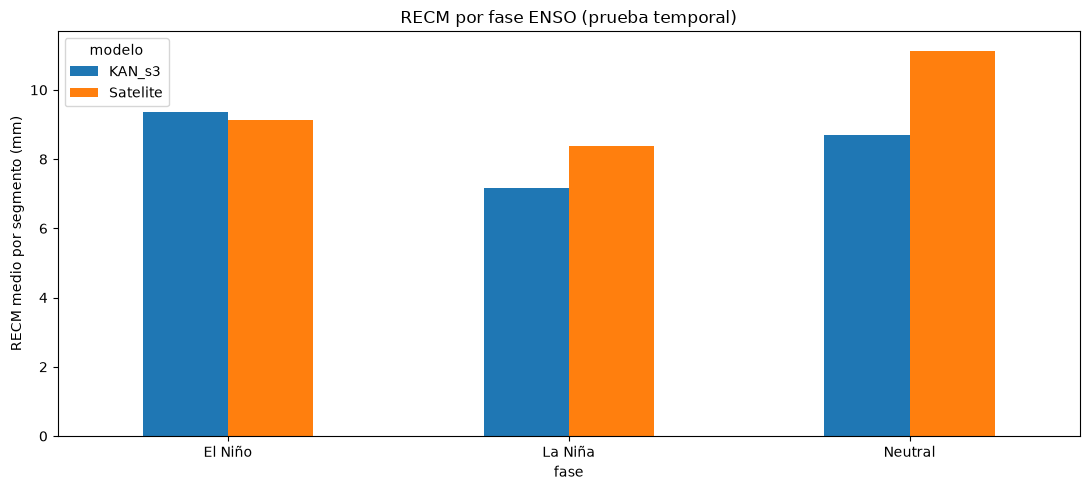

In [10]:
ruta_enso=ROOT/'data'/'enso_evaluacion.csv'
if ruta_enso.exists():
    enso=pd.read_csv(ruta_enso)
    print('Columnas ENSO:',enso.columns.to_list())
    fase_dict={(int(r.YEAR),int(r.mes_central)):str(r.fase_enso) for r in enso.itertuples()}
    # Centros aproximados de las 72 péntadas repartidas en 360 días
    fechas=pd.to_datetime('2001-01-01')+pd.to_timedelta((P-.5)*5,unit='D')
    meses=fechas.month.to_numpy()
    rows=[]
    for nombre,pred in [('Satelite',SAT),(KAN_REF,predicciones[KAN_REF])]:
        for i in np.flatnonzero(EVAL):
            fases=np.asarray([fase_dict.get((int(meta.YEAR.iloc[i]),int(m)),'Sin dato') for m in meses])
            for fase in np.unique(fases):
                ix=fases==fase
                if fase=='Sin dato':continue
                dif=pred[i,ix]-Y[i,ix]
                so=Y[i,ix].sum()
                rows.append({'modelo':nombre,'curva':ids[i],'estacion':str(meta.STATION_ID.iloc[i]),
                             'YEAR':int(meta.YEAR.iloc[i]),'fase':fase,'n_pentadas':int(ix.sum()),
                             'RECM_mm':float(np.sqrt(np.mean(dif**2))),
                             'sesgo_pct':float(100*dif.sum()/so) if so>0 else np.nan})
    ensodf=pd.DataFrame(rows)
    enso_res=ensodf.groupby(['modelo','fase']).agg(n_segmentos=('curva','size'),
                  n_pentadas=('n_pentadas','sum'),RECM_medio=('RECM_mm','mean'),
                  sesgo_pct_medio=('sesgo_pct','mean')).reset_index()
    display(enso_res.round(3))
    piv=enso_res.pivot(index='fase',columns='modelo',values='RECM_medio')
    piv.plot(kind='bar',figsize=(11,5),rot=0,title='RECM por fase ENSO (prueba temporal)')
    plt.ylabel('RECM medio por segmento (mm)');plt.tight_layout()
    plt.show()
else:
    print('No se encuentra data/enso_evaluacion.csv; omito ENSO sin inventar etiquetas.')


## Comprobación FPCA: error irrecuperable del decodificador y puntajes

Para evitar confundir la falla de la cabeza con un límite de la FPCA, proyectamos la **curva real transformada** sobre la base FPCA guardada (solo para diagnóstico). Es un **oráculo**, no un modelo predictivo, por lo que nunca debe reportarse como competidor. La figura de puntajes ayuda a detectar colapso hacia la media. La FPCA usada por las tres cabezas debe proceder únicamente de entrenamiento.

RECM del piso de reconstrucción FPCA (ORÁCULO, no predictor): 2.5150732211229694
RECM KAN: 8.937910953376045


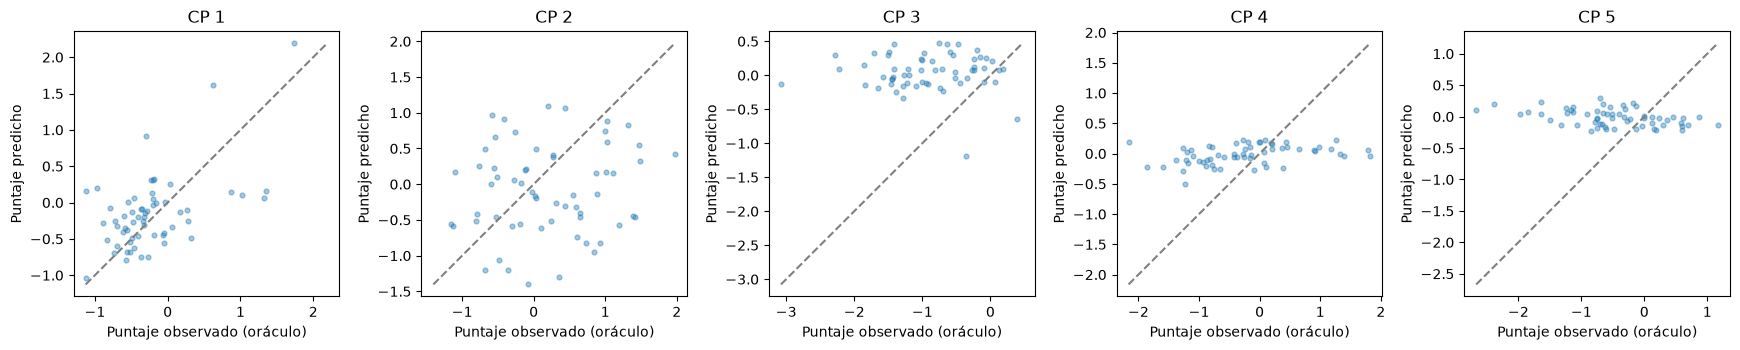

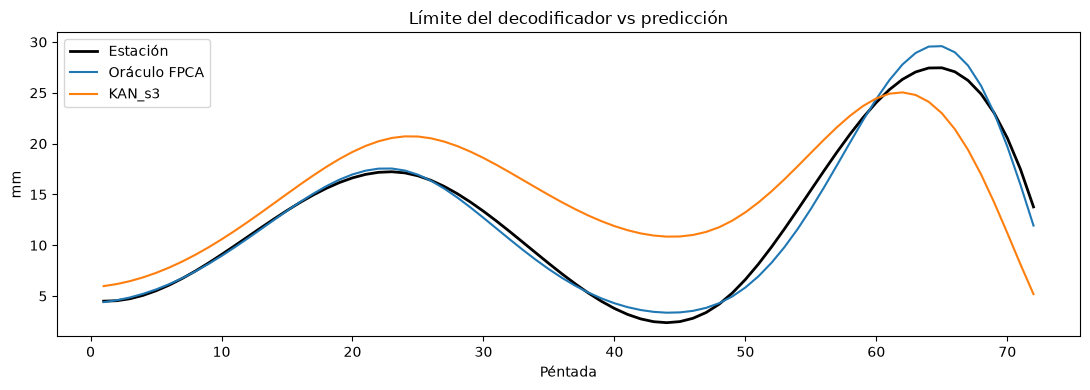

In [11]:
ck=estados[KAN_REF]
M=int(ck['M'])
# La FPCA en el checkpoint está expresada en la malla de las 72 péntadas, en la escala transformada
mu=np.asarray(ck['media_fpca'],float)
psi=np.asarray(ck['base_fpca'],float)  # M x 72, incluye escala de puntajes
phi_e=datos['phi_est'][datos['filas_pentadas']]
curvas_transformadas=datos['c_est'] @ phi_e.T
# puntajes de mínimos cuadrados en la base REAL escalada, sin presuponer ortonormalidad después del escalado
puntajes_obs=np.linalg.lstsq(psi.T,(curvas_transformadas-mu).T,rcond=None)[0].T
recon_transformada=mu+puntajes_obs@psi
escala=ck.get('escala','raiz')
recon_oraculo=mod.TRANSFORMACIONES[escala][1](np.maximum(recon_transformada,0.0))
print('RECM del piso de reconstrucción FPCA (ORÁCULO, no predictor):',
      float(np.mean(metricas_por_curva(Y,recon_oraculo)['RECM_mm'].to_numpy()[TEST])))
print('RECM KAN:',float(np.mean(metricas_por_curva(Y,predicciones[KAN_REF])['RECM_mm'].to_numpy()[TEST])))
fig,axs=plt.subplots(1,M,figsize=(3.5*M,3.6))
axs=np.atleast_1d(axs)
for j,ax in enumerate(axs):
    ax.scatter(puntajes_obs[TEST,j],scores_pred[KAN_REF][TEST,j],alpha=.4,s=12)
    lo=min(puntajes_obs[TEST,j].min(),scores_pred[KAN_REF][TEST,j].min())
    hi=max(puntajes_obs[TEST,j].max(),scores_pred[KAN_REF][TEST,j].max())
    ax.plot([lo,hi],[lo,hi],ls='--',c='gray')
    ax.set(xlabel='Puntaje observado (oráculo)',ylabel='Puntaje predicho',title=f'CP {j+1}')
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(P,Y[casos[0]],label='Estación',lw=2,color='black')
ax.plot(P,recon_oraculo[casos[0]],label='Oráculo FPCA')
ax.plot(P,predicciones[KAN_REF][casos[0]],label=KAN_REF)
ax.legend();ax.set(xlabel='Péntada',ylabel='mm',title='Límite del decodificador vs predicción');plt.tight_layout()
plt.show()


## Pesos funcionales aprendidos \(w_k(t)\)

Se grafican los ocho pesos funcionales por neurona, resaltando las dos ventanas estacionales. Los signos de los pesos no indican precipitación negativa ni prueban causalidad. 

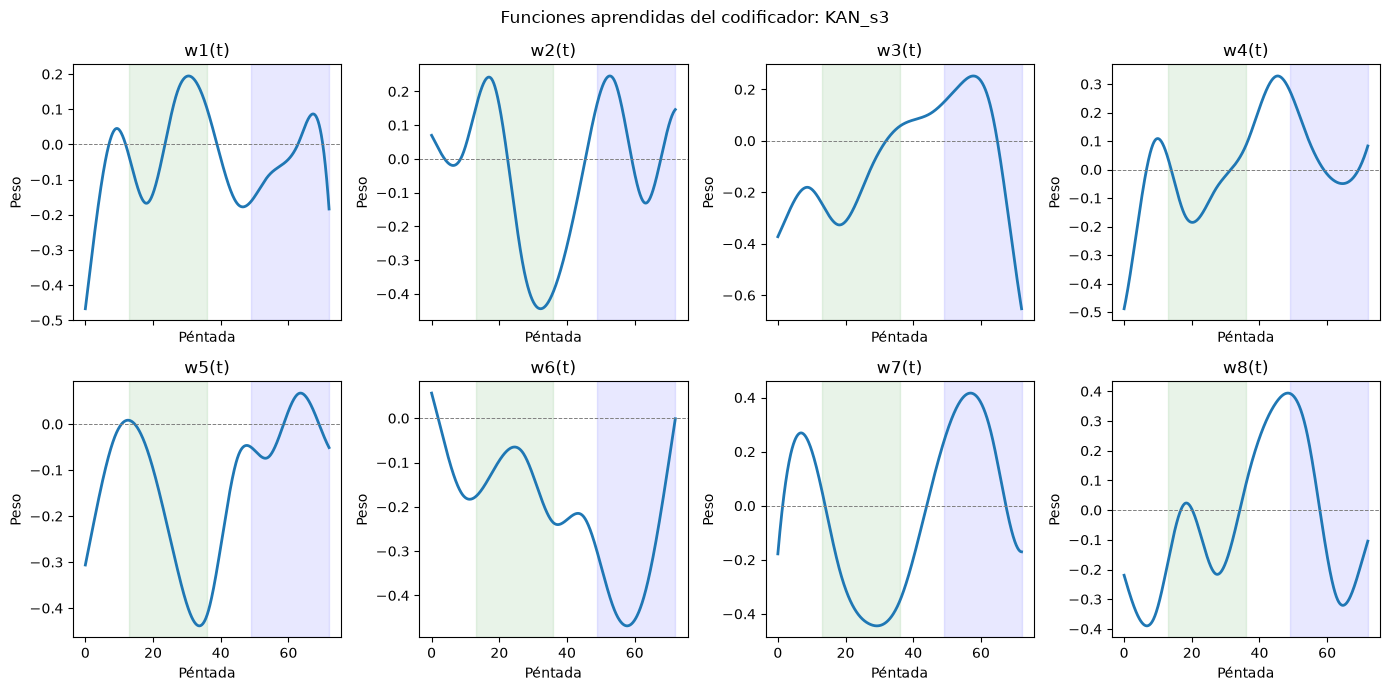

,neurona,energia_L2,rugosidad
0,1,1.2419,0.0075
1,2,3.1644,0.0058
2,3,3.6227,0.0019
3,4,1.9978,0.0036
4,5,2.7550,0.0015
5,6,4.4409,0.0009
6,7,5.8871,0.0059
7,8,4.4156,0.0053


In [12]:
modelo_kan=modelos[KAN_REF]
q=int(ck['q'])
w=modelo_kan.codificador.funciones_pesos(datos['phi_sat'])
fig,axs=plt.subplots(2,4,figsize=(14,7),sharex=True)
for j,ax in enumerate(axs.flat):
    if j>=q:ax.axis('off');continue
    ax.plot(datos['t'],w[:,j],lw=2)
    ax.axhline(0,ls='--',c='gray',lw=.7)
    ax.axvspan(13,36,alpha=.09,color='green');ax.axvspan(49,72,alpha=.09,color='blue')
    ax.set(title=f'w{j+1}(t)',xlabel='Péntada',ylabel='Peso')
fig.suptitle(f'Funciones aprendidas del codificador: {KAN_REF}')
fig.tight_layout();plt.show()
A=modelo_kan.codificador.A.detach().numpy()
energia=np.einsum('ik,kl,il->i',A,W_sat,A)
rugosidad=np.einsum('ik,kl,il->i',A,R_sat,A)
df_w=pd.DataFrame({'neurona':np.arange(1,q+1),'energia_L2':energia,'rugosidad':rugosidad})
display(df_w.round(4))


## Activaciones KAN, cobertura de la calibración y contribución real

,entrada,fuera_menos1_mas1_train_pct,fuera_menos1_mas1_test_pct,min_norm_test,max_norm_test
0,z1,16.60,18.33,0.41,1.13
1,z2,1.61,0.00,-0.35,0.71
2,z3,0.00,0.00,-0.62,0.52
3,z4,10.94,10.00,0.06,1.19
4,z5,100.00,100.00,-4.21,-1.71
5,z6,12.01,16.67,0.25,1.14
6,z7,88.29,96.67,-1.59,-0.99
7,z8,1.53,0.00,-0.79,0.08
8,Altitud,0.00,0.00,-0.66,0.29
9,ONI,0.00,0.00,-0.43,0.37


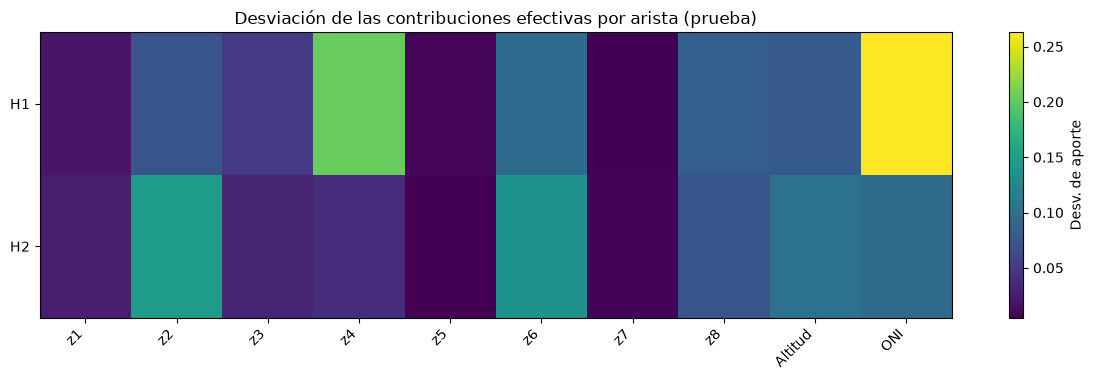

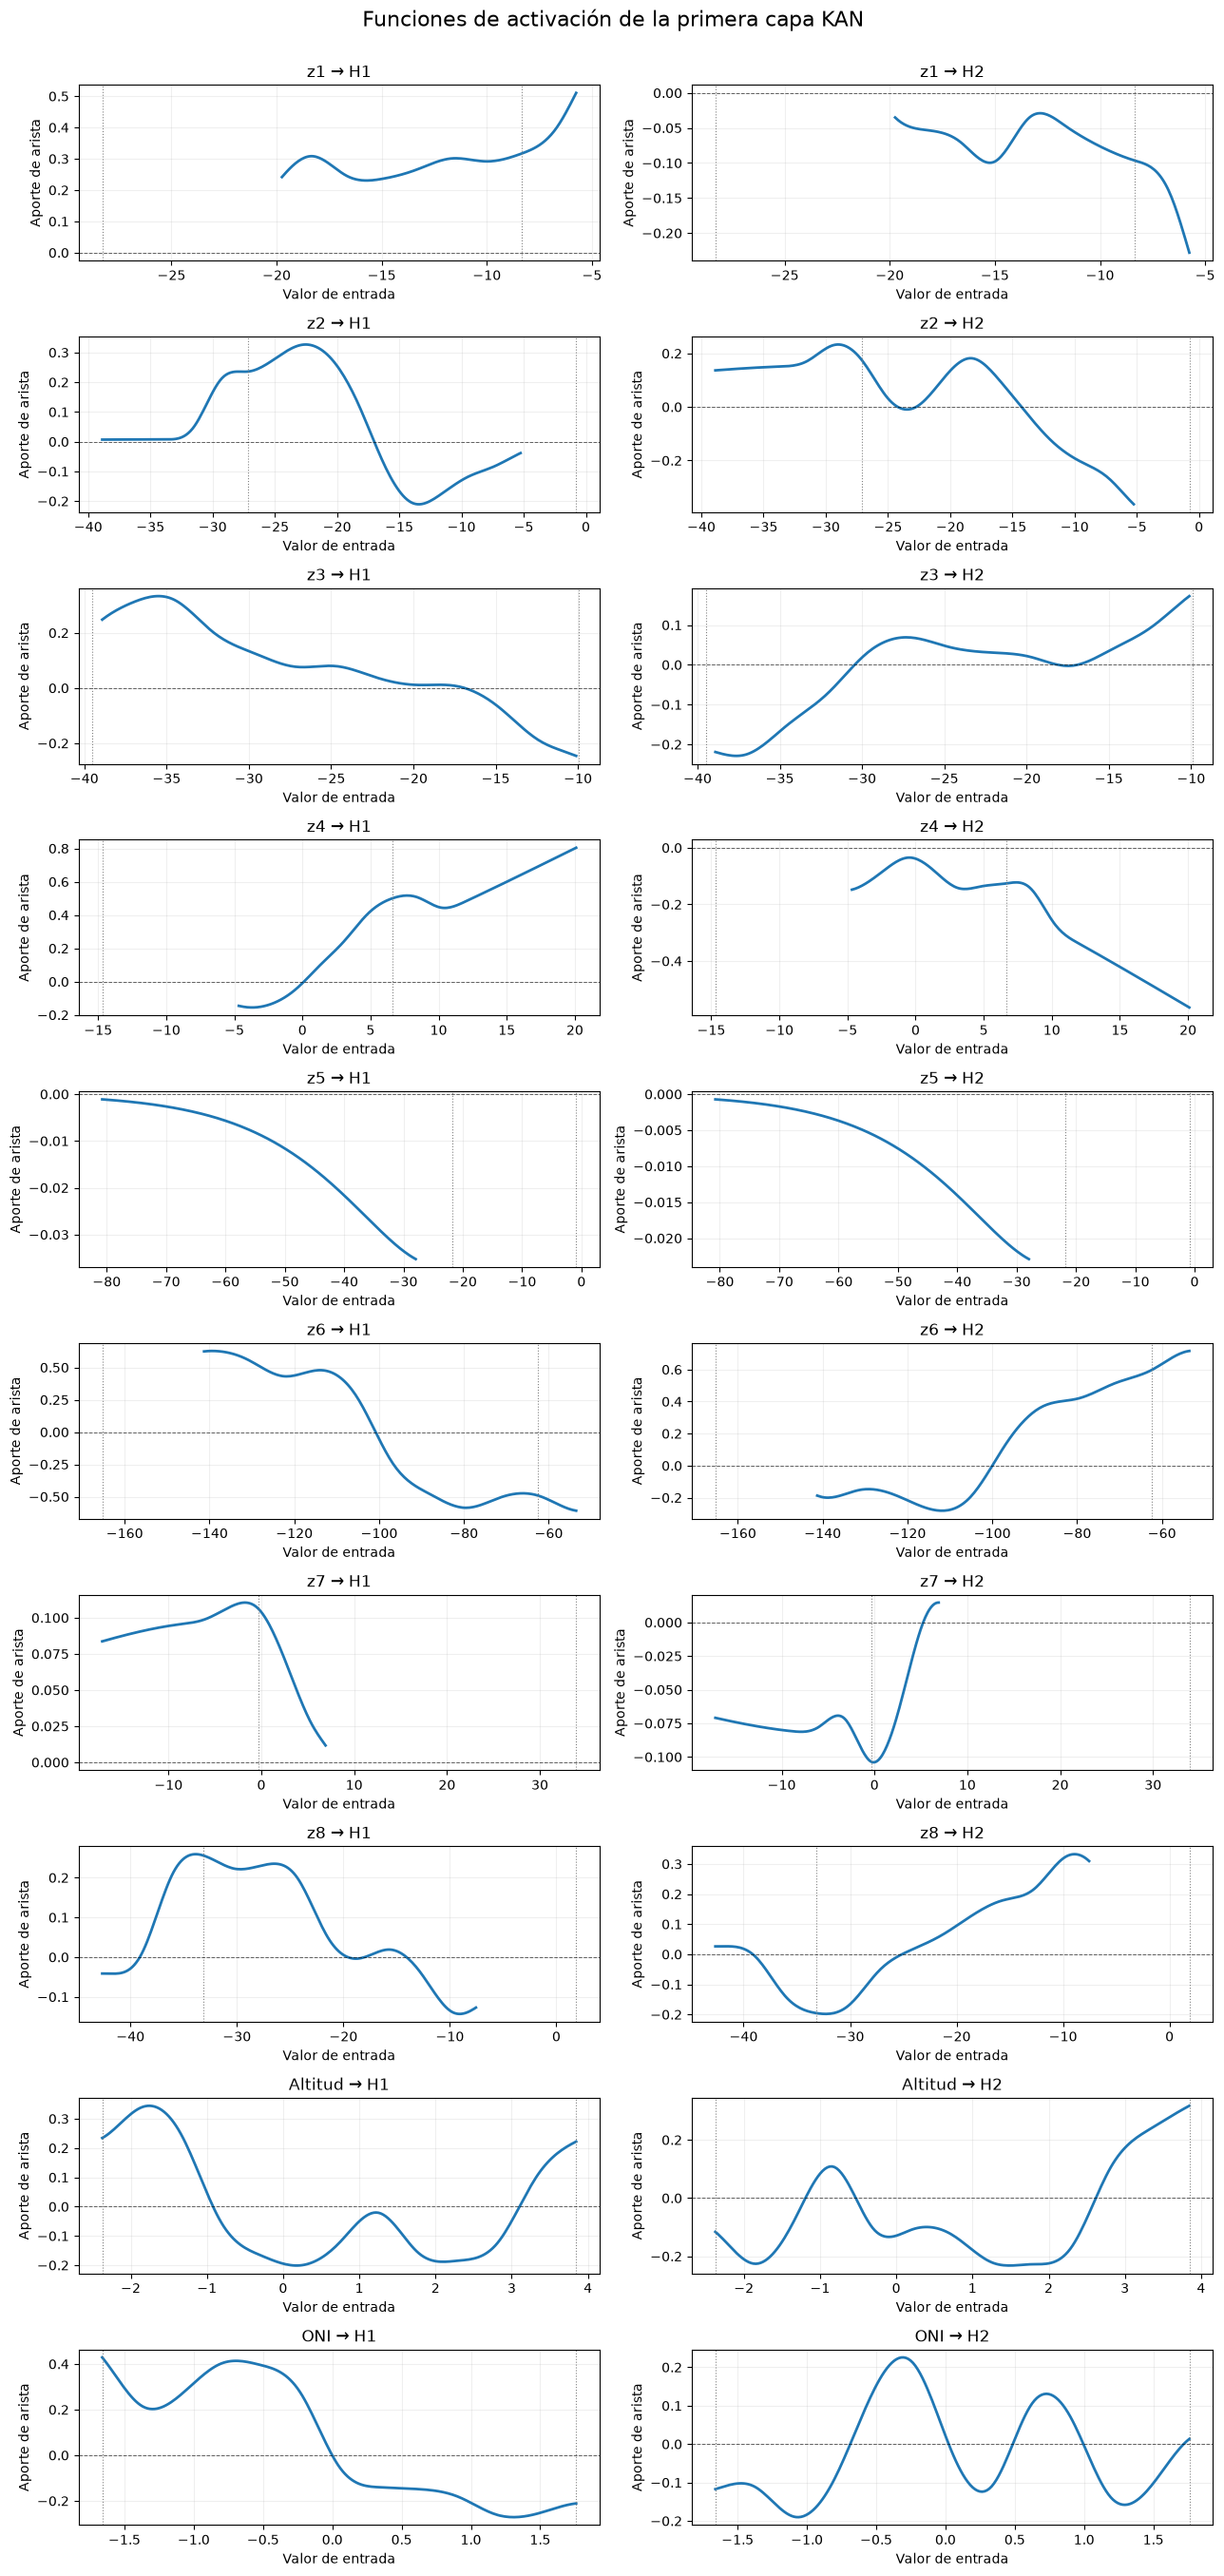

Funciones de activación graficadas: 10 entradas × 2 neuronas = 20 funciones


In [13]:
cov = (datos['cov'] - ck['media_covariables']) / ck['desviacion_covariables']

with torch.no_grad():
    H = modelo_kan.codificador(
        torch.as_tensor(datos['c_sat'], dtype=torch.float64),
        torch.as_tensor(cov, dtype=torch.float64)
    ).numpy()

cap = modelo_kan.cabeza.capas[0]
labels = [f'z{k+1}' for k in range(q)] + ['Altitud', 'ONI']
n_entradas = H.shape[1]
n_ocultas = cap.salidas

normalizado = (H - cap.centro.detach().numpy()) / cap.escala.detach().numpy()

cobertura = pd.DataFrame({
    'entrada': labels,
    'fuera_menos1_mas1_train_pct': 100 * np.mean(np.abs(normalizado[TRAIN]) > 1, axis=0),
    'fuera_menos1_mas1_test_pct': 100 * np.mean(np.abs(normalizado[TEST]) > 1, axis=0),
    'min_norm_test': normalizado[TEST].min(axis=0),
    'max_norm_test': normalizado[TEST].max(axis=0)
})

display(cobertura.round(2))

contrib = np.zeros((n_ocultas, n_entradas, int(TEST.sum())))

for j in range(n_ocultas):
    for k in range(n_entradas):
        with torch.no_grad():
            contrib[j, k] = cap.arista(j, k, torch.as_tensor(H[TEST, k], dtype=torch.float64)).numpy()

importancia = contrib.std(axis=2)

fig, ax = plt.subplots(figsize=(12, 3 + n_ocultas * 0.45))
im = ax.imshow(importancia, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(n_ocultas), [f'H{j+1}' for j in range(n_ocultas)])
ax.set_title('Desviación de las contribuciones efectivas por arista (prueba)')
fig.colorbar(im, ax=ax, label='Desv. de aporte')
fig.tight_layout()
plt.show()

importancia_train = np.zeros_like(importancia)

for j in range(n_ocultas):
    for k in range(n_entradas):
        with torch.no_grad():
            v = cap.arista(j, k, torch.as_tensor(H[TRAIN, k], dtype=torch.float64)).numpy()
        importancia_train[j, k] = np.std(v)

fig, axs = plt.subplots(n_entradas, n_ocultas, figsize=(13, 2.7 * n_entradas), squeeze=False)

for k in range(n_entradas):
    x = H[TRAIN, k]
    lo = float(np.min(x))
    hi = float(np.max(x))
    if hi <= lo:
        hi = lo + 1e-6
    grid = np.linspace(lo, hi, 200)
    centro = float(cap.centro[k].detach().item())
    escala = float(cap.escala[k].detach().item())
    limite_inferior = centro - escala
    limite_superior = centro + escala

    for j in range(n_ocultas):
        ax = axs[k, j]
        with torch.no_grad():
            v = cap.arista(j, k, torch.as_tensor(grid, dtype=torch.float64)).numpy()

        ax.plot(grid, v, linewidth=2, label='Activación KAN')
        ax.axvline(limite_inferior, color='gray', linestyle=':', linewidth=0.8)
        ax.axvline(limite_superior, color='gray', linestyle=':', linewidth=0.8)
        ax.axhline(0, color='black', linestyle='--', linewidth=0.7, alpha=0.6)
        ax.set_title(f'{labels[k]} → H{j+1}')
        ax.set_xlabel('Valor de entrada')
        ax.set_ylabel('Aporte de arista')
        ax.grid(alpha=0.2)

fig.suptitle('Funciones de activación de la primera capa KAN', fontsize=16, y=1.002)
fig.tight_layout()
plt.show()

print(f'Funciones de activación graficadas: {n_entradas} entradas × {n_ocultas} neuronas = {n_entradas * n_ocultas} funciones')

## Contraste de la KAN con los coeficientes de la cabeza lineal

La KAN tiene contribuciones dependientes de la entrada; la lineal tiene una matriz fija \(B\). Para comparar de forma descriptiva, mostramos las magnitudes de las contribuciones \(h_k B_{mk}\) para la lineal en el mismo conjunto temporal y, por separado, las de la KAN. 

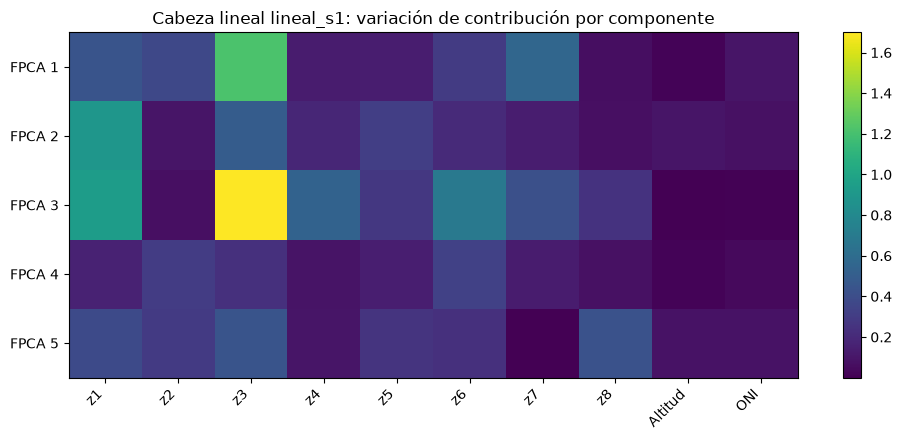

Matriz de coeficientes lineales B (filas FPCA, columnas entradas):


,z1,z2,z3,z4,z5,z6,z7,z8,Altitud,ONI
0,0.109,-0.149,0.217,-0.075,-0.074,-0.114,0.238,-0.026,-0.022,-0.174
1,0.221,0.038,0.089,0.104,-0.171,0.077,0.059,-0.030,-0.143,0.130
2,0.231,0.029,0.304,0.307,0.152,-0.263,-0.176,-0.103,-0.003,-0.018
3,-0.039,-0.123,0.043,0.053,0.078,-0.126,0.056,-0.031,0.026,0.076
4,-0.094,0.116,0.079,0.054,0.142,-0.091,0.000,-0.179,0.125,-0.152


In [14]:
if 'lineal' in REFS:
    nom=REFS['lineal']; lineal=modelos[nom]; cl=estados[nom]
    cv=(datos['cov']-cl['media_covariables'])/cl['desviacion_covariables']
    with torch.no_grad():
        h=lineal.codificador(torch.as_tensor(datos['c_sat'],dtype=torch.float64),
                             torch.as_tensor(cv,dtype=torch.float64)).numpy()
    B=lineal.cabeza.capa.weight.detach().numpy() # [M,q+2]
    aportes=h[TEST,:,None]*B.T[None,:,:] # [casos, q+2, M]
    fig,ax=plt.subplots(figsize=(10,4.5))
    v=np.std(aportes,axis=0).T
    img=ax.imshow(v,aspect='auto',cmap='viridis')
    ax.set_yticks(range(v.shape[0]),[f'FPCA {k+1}' for k in range(v.shape[0])])
    ax.set_xticks(range(v.shape[1]),[f'z{k+1}' for k in range(v.shape[1]-2)]+['Altitud','ONI'],rotation=45,ha='right')
    ax.set_title(f'Cabeza lineal {nom}: variación de contribución por componente')
    fig.colorbar(img,ax=ax);fig.tight_layout();plt.show()
    print('Matriz de coeficientes lineales B (filas FPCA, columnas entradas):')
    display(pd.DataFrame(B,columns=[f'z{k+1}' for k in range(B.shape[1]-2)]+['Altitud','ONI']).round(3))


## Ajuste simbólico de una activación KAN 

Arista: ONI -> H1 
R2 en puntos alternos no usados en ajuste: 0.898139
u=(x-centro)/escala; centro= 0.049476005991745065 escala= 1.7099121655400769
phi_aprox(u)= (+0.0682358) + (-0.7094938)*u^1 + (-0.04923216)*u^2 + (+0.5160239)*u^3


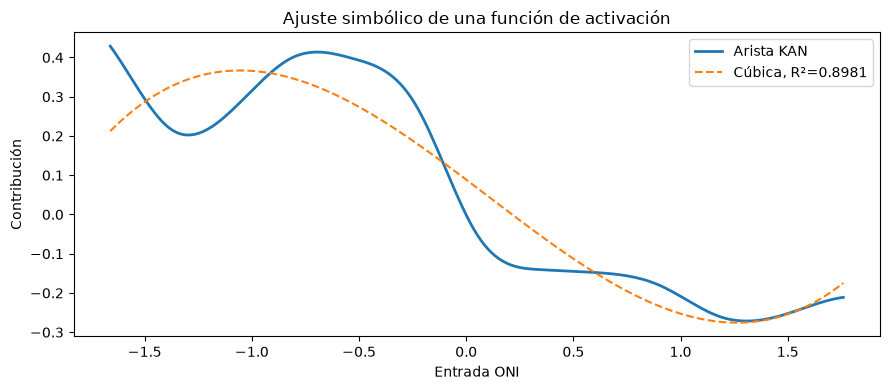

In [15]:
variabilidad_train=np.zeros_like(importancia)
for j in range(n_ocultas):
    for k in range(H.shape[1]):
        with torch.no_grad():
            v=cap.arista(j,k,torch.as_tensor(H[TRAIN,k],dtype=torch.float64)).numpy()
        variabilidad_train[j,k]=np.std(v)
j,k=np.unravel_index(np.argmax(variabilidad_train),variabilidad_train.shape)
lo,hi=np.quantile(H[TRAIN,k],[.01,.99]);hi=max(hi,lo+1e-6)
rejilla=torch.linspace(float(lo),float(hi),201,dtype=torch.float64)
coef,aprox,r2=mod.ajustar_simbolica(cap,int(j),int(k),rejilla)
with torch.no_grad(): original=cap.arista(int(j),int(k),rejilla).numpy()
u=((rejilla-cap.centro[k])/cap.escala[k]).numpy()
coef=coef.detach().numpy()
formula=' + '.join(f'({v:+.7g})*u^{p}' if p else f'({v:+.7g})' for p,v in enumerate(coef))
print('Arista:',labels[k],f'-> H{j+1}', '\nR2 en puntos alternos no usados en ajuste:',round(float(r2),6))
print('u=(x-centro)/escala; centro=',float(cap.centro[k]),'escala=',float(cap.escala[k]))
print('phi_aprox(u)=',formula)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(rejilla.numpy(),original,label='Arista KAN',lw=2)
ax.plot(rejilla.numpy(),aprox.detach().numpy(),ls='--',label=f'Cúbica, R²={r2:.4f}')
ax.set(xlabel=f'Entrada {labels[k]}',ylabel='Contribución',title='Ajuste simbólico de una función de activación')
ax.legend();fig.tight_layout();plt.show()


,YEAR,ONI_promedio,ONI_min,ONI_max,ONI_rango,ONI_desv,Meses_ONI_positivo,Meses_ONI_negativo
20,2001,-0.283,-0.8,0.0,0.8,0.217,0,11
21,2002,0.533,-0.1,1.2,1.3,0.427,11,1
22,2003,0.233,-0.2,0.9,1.1,0.303,9,2


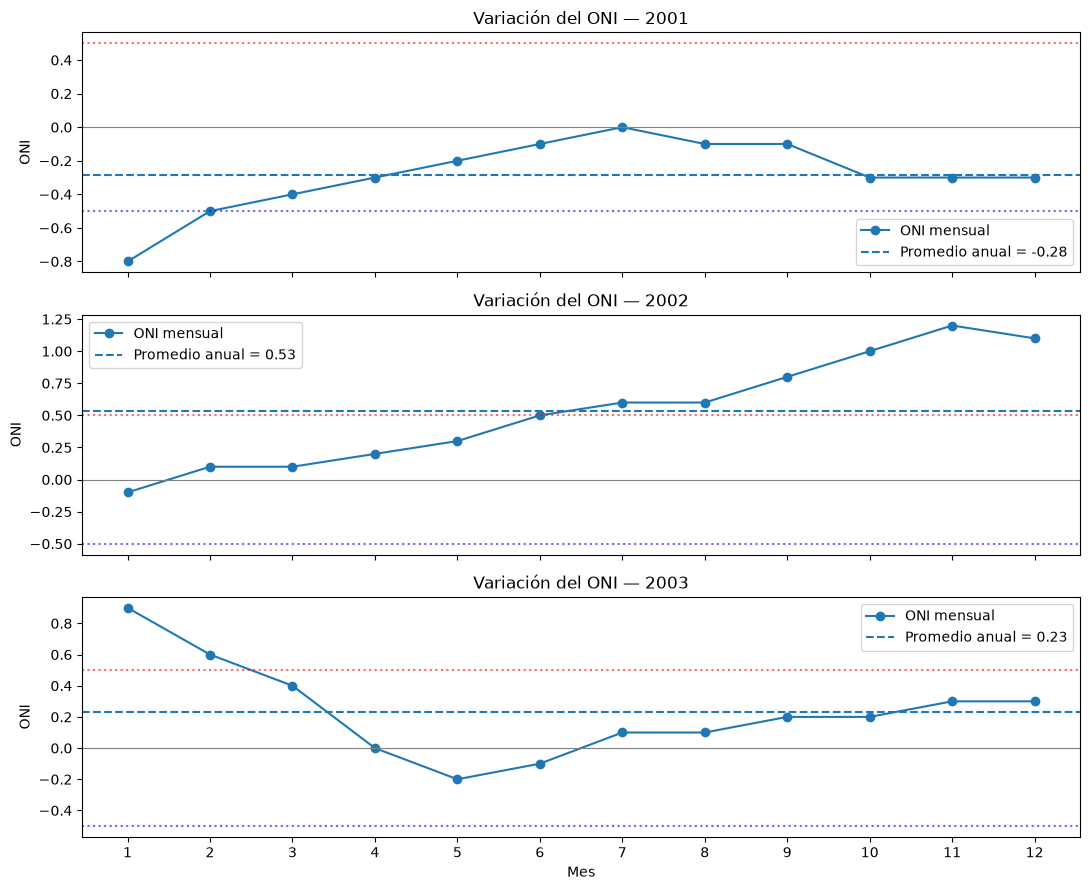

Rango temporal medio del ONI: 1.396
Años con ONI de ambos signos: 9


In [16]:
enso_diag = pd.read_csv(ROOT / "data" / "enso_evaluacion.csv")

oni_mensual = (
    enso_diag.pivot_table(
        index="YEAR",
        columns="mes_central",
        values="ONI",
        aggfunc="mean"
    )
    .reindex(columns=range(1, 13))
    .sort_index()
)

assert oni_mensual.notna().all().all(), "Hay meses ONI faltantes."

resumen_oni = pd.DataFrame({
    "YEAR": oni_mensual.index,
    "ONI_promedio": oni_mensual.mean(axis=1).values,
    "ONI_min": oni_mensual.min(axis=1).values,
    "ONI_max": oni_mensual.max(axis=1).values,
    "ONI_rango": (
        oni_mensual.max(axis=1) -
        oni_mensual.min(axis=1)
    ).values,
    "ONI_desv": oni_mensual.std(axis=1).values,
    "Meses_ONI_positivo": (oni_mensual > 0).sum(axis=1).values,
    "Meses_ONI_negativo": (oni_mensual < 0).sum(axis=1).values
})

resumen_oni_prueba = resumen_oni[resumen_oni['YEAR'].between(2001,2003)].copy()
display(resumen_oni_prueba.round(3))

# Elegir años representativos según las anomalías.
anios_ejemplo = list(resumen_oni_prueba['YEAR'].astype(int))

fig, axs = plt.subplots(
    len(anios_ejemplo), 1,
    figsize=(11, 3 * len(anios_ejemplo)),
    sharex=True
)
axs = np.atleast_1d(axs)

for ax, anio in zip(axs, anios_ejemplo):
    valores = oni_mensual.loc[anio].values
    promedio = valores.mean()

    ax.plot(range(1, 13), valores, marker="o", label="ONI mensual")
    ax.axhline(promedio, linestyle="--",
               label=f"Promedio anual = {promedio:.2f}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axhline(0.5, color="red", linestyle=":", alpha=0.6)
    ax.axhline(-0.5, color="blue", linestyle=":", alpha=0.6)
    ax.set_title(f"Variación del ONI — {anio}")
    ax.set_ylabel("ONI")
    ax.legend()

axs[-1].set_xticks(range(1, 13))
axs[-1].set_xlabel("Mes")
plt.tight_layout()
plt.show()

print("Rango temporal medio del ONI:",
      round(resumen_oni.ONI_rango.mean(), 3))
print("Años con ONI de ambos signos:",
      int(((oni_mensual.min(axis=1) < 0) &
           (oni_mensual.max(axis=1) > 0)).sum()))


Diferencia máxima entre ONI anual original y tabla mensual: 3.3306690738754696e-15


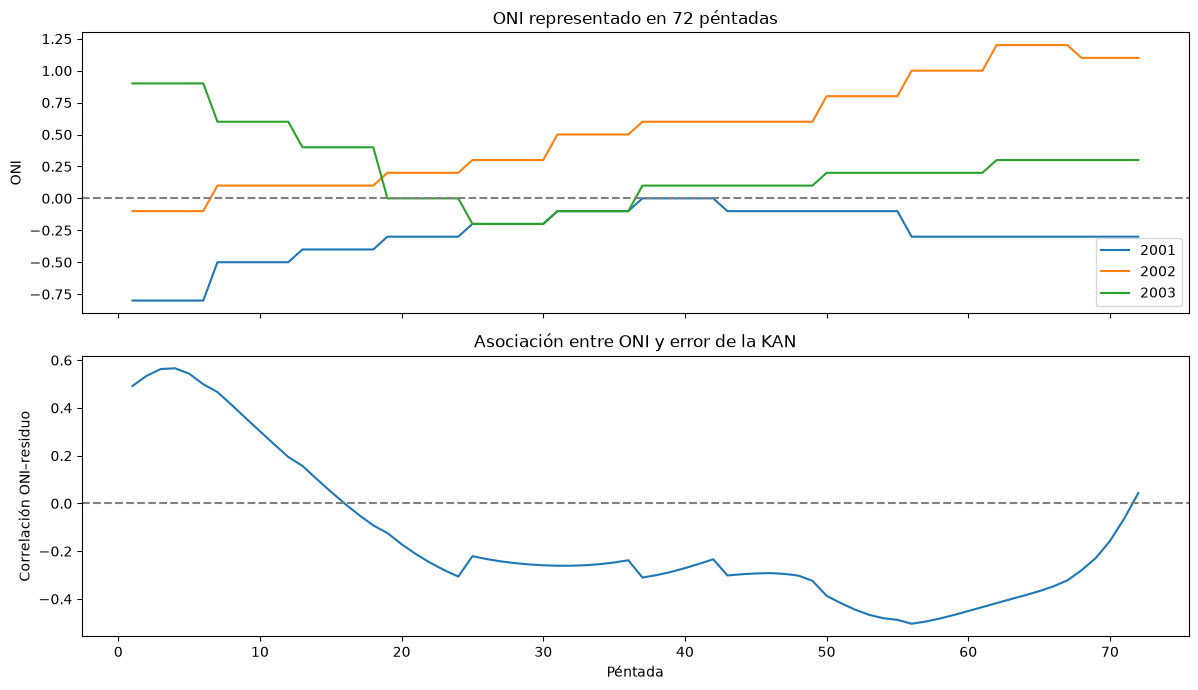

,Pentada,Mes,Correlacion_ONI_residuo
0,1,1,0.492
1,2,1,0.535
2,3,1,0.563
3,4,1,0.566
4,5,1,0.544
...,...,...,...
67,68,12,-0.280
68,69,12,-0.229
69,70,12,-0.158
70,71,12,-0.064


In [17]:
fechas_p = pd.Timestamp("2001-01-01") + pd.to_timedelta((P - 0.5) * 5, unit="D")
meses_p = fechas_p.month.to_numpy()

ONI_funcional = np.full((len(meta), len(P)), np.nan)

for i, anio in enumerate(meta["YEAR"].astype(int)):
    if anio in oni_mensual.index:
        ONI_funcional[i] = oni_mensual.loc[anio, meses_p].to_numpy()

assert np.isfinite(ONI_funcional).all()

oni_actual = meta["oni_promedio"].to_numpy(float)
oni_tabla = meta["YEAR"].map(oni_mensual.mean(axis=1)).to_numpy(float)

print("Diferencia máxima entre ONI anual original y tabla mensual:", np.max(np.abs(oni_actual - oni_tabla)))

residuo_kan = predicciones[KAN_REF] - Y

correlaciones = []
for j, pentada in enumerate(P):
    x = ONI_funcional[EVAL, j]
    e = residuo_kan[EVAL, j]
    r = np.corrcoef(x, e)[0, 1] if np.std(x) > 1e-10 and np.std(e) > 1e-10 else np.nan
    correlaciones.append(r)

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for anio in anios_ejemplo:
    i = np.flatnonzero(meta.YEAR.to_numpy() == anio)[0]
    axs[0].plot(P, ONI_funcional[i], label=str(anio))

axs[0].axhline(0, color="gray", linestyle="--")
axs[0].set_ylabel("ONI")
axs[0].set_title("ONI representado en 72 péntadas")
axs[0].legend()

axs[1].plot(P, correlaciones)
axs[1].axhline(0, color="gray", linestyle="--")
axs[1].set_ylabel("Correlación ONI–residuo")
axs[1].set_xlabel("Péntada")
axs[1].set_title("Asociación entre ONI y error de la KAN")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"Pentada": P, "Mes": meses_p, "Correlacion_ONI_residuo": correlaciones}).round(3))

## Verificar qué entradas están fuera del soporte de las B-splines KAN

Se comparan los valores finales del codificador funcional con los intervalos de calibración de la primera capa KAN. Se calcula el porcentaje de entradas fuera del soporte efectivo de las B-splines y se distingue su contribución de la parte SiLU.

,Entrada,Fuera_soporte_Train_pct,Media_Train,DE_Train,Fuera_soporte_Valid_pct,Media_Valid,DE_Valid,Fuera_soporte_Test_pct,Media_Test,DE_Test
0,z1,0.000,0.792,0.210,0.000,0.794,0.207,0.0,0.811,0.188
1,z2,0.383,0.085,0.316,0.000,0.159,0.293,0.0,0.240,0.278
2,z3,0.000,0.141,0.336,0.000,0.081,0.284,0.0,0.004,0.246
3,z4,1.071,0.653,0.296,0.943,0.678,0.243,0.0,0.621,0.256
4,z5,100.000,-2.955,0.732,100.000,-2.936,0.724,100.0,-2.823,0.712
5,z6,0.000,0.729,0.242,0.000,0.771,0.233,0.0,0.756,0.222
6,z7,23.106,-1.301,0.260,15.094,-1.290,0.195,25.0,-1.354,0.162
7,z8,0.077,-0.284,0.303,0.000,-0.286,0.231,0.0,-0.273,0.206
8,Altitud,0.000,-0.237,0.322,0.000,-0.287,0.211,0.0,-0.287,0.220
9,ONI,0.000,-0.029,0.585,0.000,-0.294,0.749,0.0,-0.002,0.332


Soporte B-spline: [-1.500, 1.500)


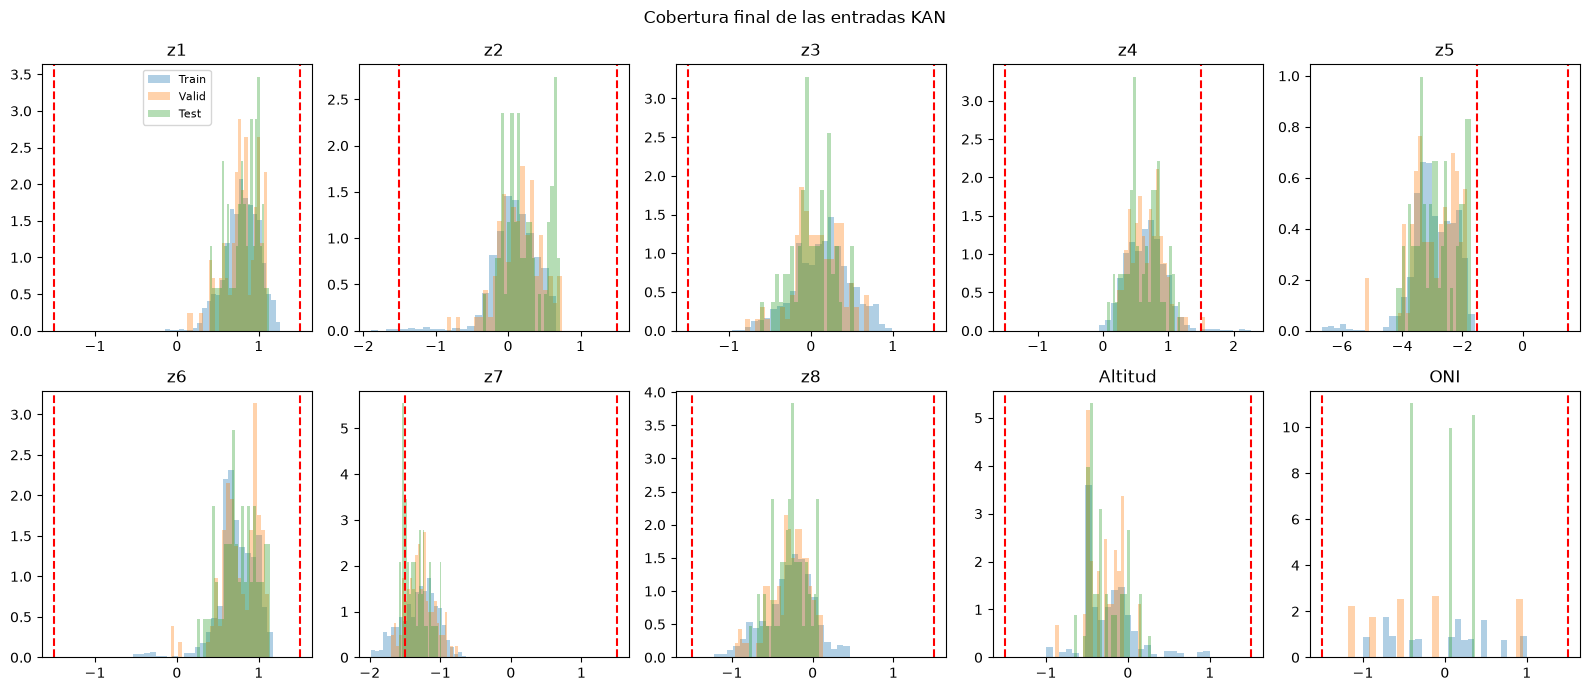

,Entrada,Spline_media_abs,SiLU_media_abs,Spline_casi_cero_pct
0,z1,0.0904,0.2565,0.0
1,z2,0.1029,0.0501,0.0
2,z3,0.0577,0.0066,0.0
3,z4,0.0707,0.1394,0.0
4,z5,0.0000,0.0176,100.0
5,z6,0.1865,0.3046,0.0
6,z7,0.0042,0.0886,25.0
7,z8,0.0857,0.0143,0.0
8,Altitud,0.1204,0.0344,0.0
9,ONI,0.1459,0.0279,0.0


In [18]:
modelo_diag = modelos[KAN_REF]
ck_diag = estados[KAN_REF]

cov_diag = (datos["cov"] - ck_diag["media_covariables"]) / ck_diag["desviacion_covariables"]

with torch.no_grad():
    entradas_kan = modelo_diag.codificador(
        torch.as_tensor(datos["c_sat"], dtype=torch.float64),
        torch.as_tensor(cov_diag, dtype=torch.float64)
    ).numpy()

capa1 = modelo_diag.cabeza.capas[0]
centros = capa1.centro.detach().numpy()
escalas = capa1.escala.detach().numpy()

z_norm = (entradas_kan - centros) / escalas
labels_z = [f"z{i+1}" for i in range(int(ck_diag["q"]))] + ["Altitud", "ONI"]

soporte_min = float(capa1.nudos[0])
soporte_max = float(capa1.nudos[-1])

filas = []

for j, nombre in enumerate(labels_z):
    fila = {"Entrada": nombre}
    for etiqueta, mascara in [("Train", TRAIN), ("Valid", VALID), ("Test", TEST)]:
        valores = z_norm[mascara, j]
        fuera = (valores < soporte_min) | (valores >= soporte_max)
        fila[f"Fuera_soporte_{etiqueta}_pct"] = 100 * fuera.mean()
        fila[f"Media_{etiqueta}"] = valores.mean()
        fila[f"DE_{etiqueta}"] = valores.std()
    filas.append(fila)

tabla_soporte = pd.DataFrame(filas)
display(tabla_soporte.round(3))

print(f"Soporte B-spline: [{soporte_min:.3f}, {soporte_max:.3f})")

fig, axs = plt.subplots(2, 5, figsize=(16, 7))
axs = axs.flatten()

for j, ax in enumerate(axs[:len(labels_z)]):
    for mascara, nombre in [(TRAIN, "Train"), (VALID, "Valid"), (TEST, "Test")]:
        ax.hist(z_norm[mascara, j], bins=25, density=True, alpha=0.35, label=nombre)
    ax.axvline(soporte_min, color="red", linestyle="--")
    ax.axvline(soporte_max, color="red", linestyle="--")
    ax.set_title(labels_z[j])

for ax in axs[len(labels_z):]:
    ax.axis("off")

axs[0].legend(fontsize=8)
fig.suptitle("Cobertura final de las entradas KAN")
plt.tight_layout()
plt.show()

registros = []

for j, nombre in enumerate(labels_z):
    x = torch.as_tensor(z_norm[TEST, j], dtype=torch.float64)
    with torch.no_grad():
        bases = capa1.bases(x)
        coef = capa1.coeficientes[:, j, :] * capa1.peso_spline[:, j, None]
        aporte_spline = bases @ coef.T
        aporte_silu = torch.nn.functional.silu(x)[:, None] * capa1.peso_base[:, j][None, :]

    registros.append({
        "Entrada": nombre,
        "Spline_media_abs": aporte_spline.abs().mean().item(),
        "SiLU_media_abs": aporte_silu.abs().mean().item(),
        "Spline_casi_cero_pct": (aporte_spline.abs() < 1e-10).double().mean().item() * 100
    })

display(pd.DataFrame(registros).round(4))

## Diagnosticar el aprendizaje de las cinco componentes FPCA

Se compara cada puntaje FPCA predicho con su valor de referencia, obtenido proyectando la curva terrestre en el espacio del decodificador. Se cuantifica la correlación, la desviación estándar, el error y el sesgo de cada componente.

Este análisis permite identificar qué componentes son aprovechadas por la red y cuáles presentan predicciones comprimidas hacia cero o una escasa relación con los valores observados.

,Modelo,Componente,DE_observada,DE_predicha,Ratio_DE,Correlacion,RECM_puntaje,Sesgo_puntaje
0,KAN_s3,1,0.5670,0.5142,0.9069,0.5505,0.5213,0.0829
1,KAN_s3,2,0.7515,0.6228,0.8287,0.1248,0.9586,-0.2880
2,KAN_s3,3,0.6771,0.2721,0.4019,-0.0280,1.2039,0.9521
3,KAN_s3,4,0.8793,0.1584,0.1801,0.3608,0.8672,0.2330
4,KAN_s3,5,0.7823,0.1306,0.1670,-0.4123,0.9747,0.4866


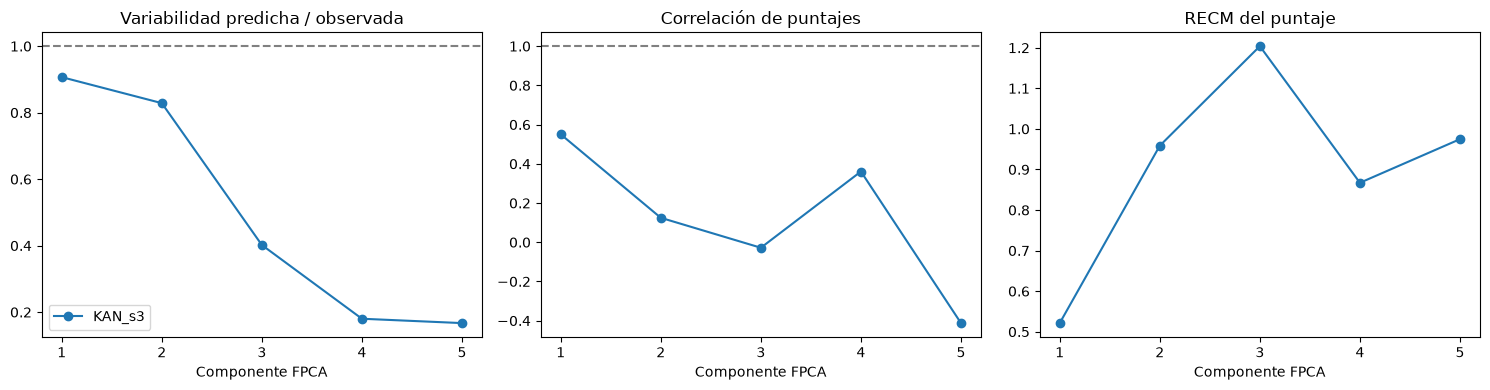

In [19]:
registros_fpca = []

for nombre in [KAN_REF]:
    ck_local = estados[nombre]
    assert np.allclose(ck_local["base_fpca"], ck_diag["base_fpca"]), f"Base FPCA diferente en {nombre}"

    for j in range(int(ck_local["M"])):
        observado = puntajes_obs[TEST, j]
        predicho = scores_pred[nombre][TEST, j]
        de_o = np.std(observado)
        de_p = np.std(predicho)
        correlacion = np.corrcoef(observado, predicho)[0, 1] if de_o > 1e-10 and de_p > 1e-10 else np.nan

        registros_fpca.append({
            "Modelo": nombre,
            "Componente": j + 1,
            "DE_observada": de_o,
            "DE_predicha": de_p,
            "Ratio_DE": de_p / de_o if de_o > 1e-10 else np.nan,
            "Correlacion": correlacion,
            "RECM_puntaje": np.sqrt(np.mean((predicho - observado)**2)),
            "Sesgo_puntaje": np.mean(predicho - observado)
        })

diagnostico_fpca = pd.DataFrame(registros_fpca)
display(diagnostico_fpca.round(4))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for nombre, tabla in diagnostico_fpca.groupby("Modelo"):
    axs[0].plot(tabla.Componente, tabla.Ratio_DE, marker="o", label=nombre)
    axs[1].plot(tabla.Componente, tabla.Correlacion, marker="o", label=nombre)
    axs[2].plot(tabla.Componente, tabla.RECM_puntaje, marker="o", label=nombre)

axs[0].axhline(1, color="gray", linestyle="--")
axs[1].axhline(1, color="gray", linestyle="--")

axs[0].set_title("Variabilidad predicha / observada")
axs[1].set_title("Correlación de puntajes")
axs[2].set_title("RECM del puntaje")

for ax in axs:
    ax.set_xlabel("Componente FPCA")
    ax.set_xticks(range(1, int(ck_diag["M"]) + 1))

axs[0].legend()
plt.tight_layout()
plt.show()

## Evaluar si el modelo falla más en eventos de lluvia intensa

Se evalúa el comportamiento de la KAN, el MLP, la cabeza lineal y el satélite en función de la intensidad de la lluvia en la curva de la estación. Los intervalos se construyen utilizando percentiles del conjunto de entrenamiento para evitar seleccionar umbrales a partir de los datos de prueba.

Esta prueba permite identificar si los modelos están reduciendo los errores principalmente en periodos de precipitación baja o moderada, pero subestimando los eventos de mayor intensidad.

,Modelo,Intensidad,N_puntos,Precipitacion_observada_media,Precipitacion_predicha_media,Sesgo_mm,RECM_mm,MAE_mm
0,Satélite,Hasta P50,2244,10.412,18.345,7.933,11.658,9.011
1,Satélite,P50-P75,1170,24.049,29.152,5.103,11.132,8.632
2,Satélite,P75-P90,663,34.626,32.314,-2.312,9.834,8.028
3,Satélite,P90-P95,143,46.783,40.154,-6.629,12.170,9.796
4,Satélite,Superior P95,100,65.793,52.814,-12.980,16.769,14.528
5,KAN,Hasta P50,2244,10.412,14.696,4.283,7.779,6.055
6,KAN,P50-P75,1170,24.049,22.507,-1.542,8.060,6.021
7,KAN,P75-P90,663,34.626,27.029,-7.596,11.720,9.855
8,KAN,P90-P95,143,46.783,34.147,-12.637,19.638,17.839
9,KAN,Superior P95,100,65.793,42.986,-22.807,28.771,24.360


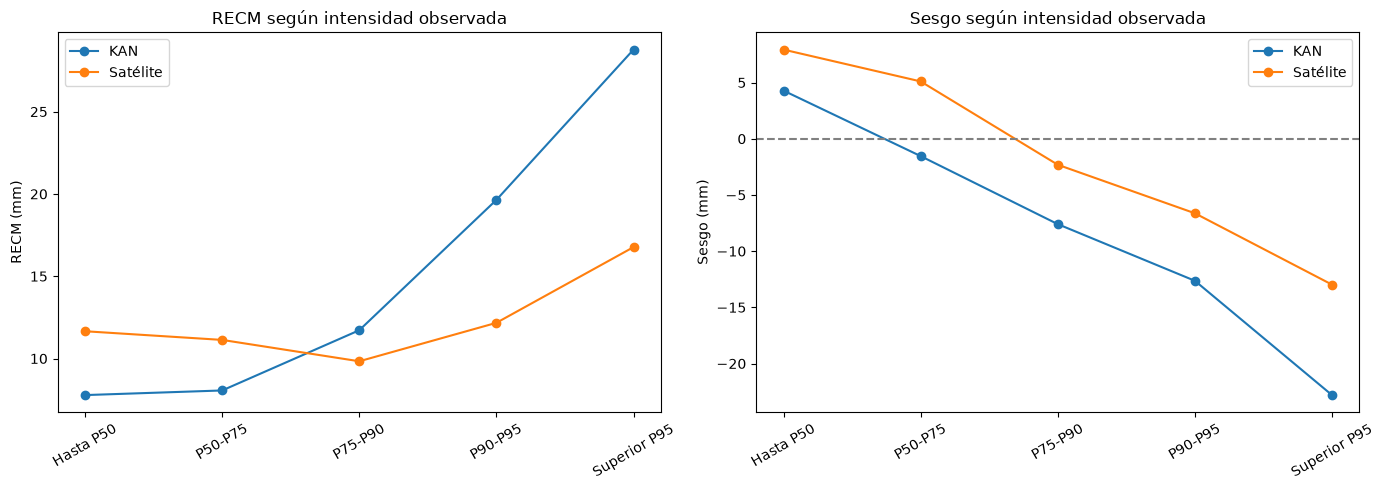

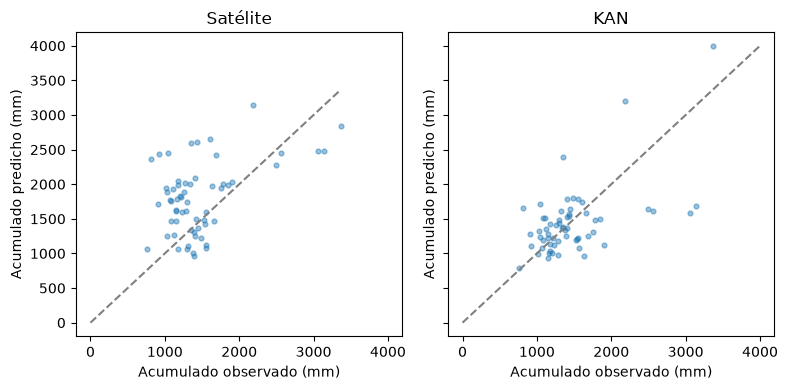

In [20]:
valores_train = Y[TRAIN].ravel()
valores_train = valores_train[np.isfinite(valores_train)]

q50, q75, q90, q95 = np.quantile(valores_train, [0.50, 0.75, 0.90, 0.95])
umbrales = [-np.inf, q50, q75, q90, q95, np.inf]
etiquetas_int = ["Hasta P50", "P50-P75", "P75-P90", "P90-P95", "Superior P95"]

modelos_int = {"Satélite": SAT, "KAN": predicciones[KAN_REF]}
filas_int = []
observado = Y[EVAL]

for nombre, pred in modelos_int.items():
    predicho = pred[EVAL]
    for j, etiqueta in enumerate(etiquetas_int):
        seleccion = (observado > umbrales[j]) & (observado <= umbrales[j+1])
        obs_g = observado[seleccion]
        pred_g = predicho[seleccion]
        if len(obs_g) == 0:
            continue
        diferencia = pred_g - obs_g
        filas_int.append({
            "Modelo": nombre,
            "Intensidad": etiqueta,
            "N_puntos": len(obs_g),
            "Precipitacion_observada_media": obs_g.mean(),
            "Precipitacion_predicha_media": pred_g.mean(),
            "Sesgo_mm": diferencia.mean(),
            "RECM_mm": np.sqrt(np.mean(diferencia**2)),
            "MAE_mm": np.mean(np.abs(diferencia))
        })

tabla_intensidad = pd.DataFrame(filas_int)
display(tabla_intensidad.round(3))

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for nombre, grupo in tabla_intensidad.groupby("Modelo"):
    grupo = grupo.set_index("Intensidad").reindex(etiquetas_int)
    axs[0].plot(etiquetas_int, grupo["RECM_mm"], marker="o", label=nombre)
    axs[1].plot(etiquetas_int, grupo["Sesgo_mm"], marker="o", label=nombre)

axs[0].set_title("RECM según intensidad observada")
axs[0].set_ylabel("RECM (mm)")
axs[1].set_title("Sesgo según intensidad observada")
axs[1].set_ylabel("Sesgo (mm)")
axs[1].axhline(0, color="gray", linestyle="--")

for ax in axs:
    ax.tick_params(axis="x", rotation=30)
    ax.legend()

plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, len(modelos_int), figsize=(4*len(modelos_int), 4), sharex=True, sharey=True)

for ax, (nombre, pred) in zip(np.atleast_1d(axs), modelos_int.items()):
    obs_acum = Y[EVAL].sum(axis=1)
    pred_acum = pred[EVAL].sum(axis=1)
    ax.scatter(obs_acum, pred_acum, s=12, alpha=0.45)
    limite = max(obs_acum.max(), pred_acum.max())
    ax.plot([0, limite], [0, limite], linestyle="--", color="gray")
    ax.set_title(nombre)
    ax.set_xlabel("Acumulado observado (mm)")
    ax.set_ylabel("Acumulado predicho (mm)")

plt.tight_layout()
plt.show()

## Peores casos de la KAN seleccionada

Se analizan las seis curvas de prueba con mayor L² relativo, junto con altitud, KGE, sesgo anual y error de ambos picos. La interpretación debe contrastar los eventos intensos, los desfases y el régimen bimodal sin atribuir automáticamente causalidad a ENSO u orografía.

,curva,STATION_ID,YEAR,altitud,L2_relativo,KGE,sesgo_anual_pct,error_Pico_1_MarJun_dias,error_Pico_2_SepDic_dias
0,5420410115_2001,5420410115,2001,990.0,1.079,-0.200,105.230,45,20
1,5420410117_2001,5420410117,2001,1850.0,0.752,0.195,77.579,25,20
2,2612710105_2003,2612710105,2003,2160.0,0.670,0.241,65.323,50,10
3,2624000102_2001,2624000102,2001,1000.0,0.576,0.317,40.198,10,25
4,2622420101_2003,2622420101,2003,1260.0,0.551,0.475,39.872,20,5
5,5301400108_2002,5301400108,2002,650.0,0.547,0.390,46.513,10,10


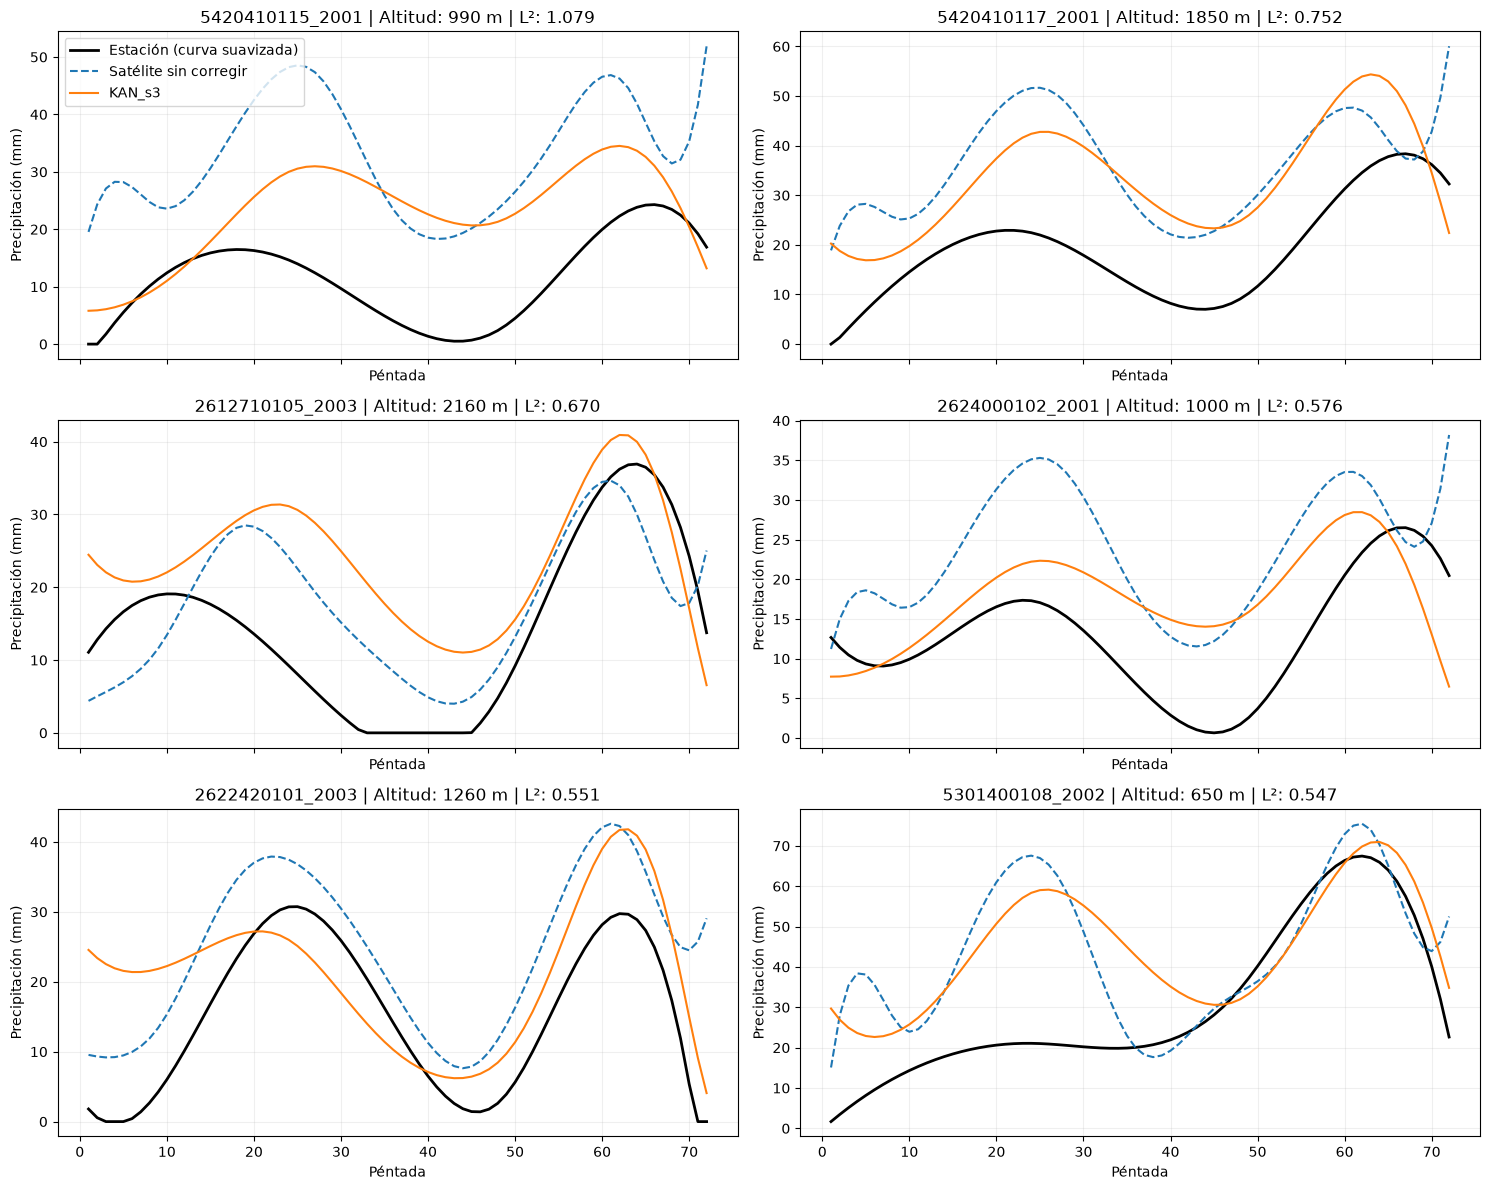

In [21]:
peores = metricas[KAN_REF].sort_values('L2_relativo',ascending=False).head(6).copy()
geo = meta[['curva','altitud','latitud','longitud']].copy()
peores = peores.merge(geo,on='curva',how='left')
columnas_mostrar = ['curva','STATION_ID','YEAR','altitud','L2_relativo','KGE',
                    'sesgo_anual_pct','error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias']
display(peores[columnas_mostrar].round(3))
fig,axs=plt.subplots(3,2,figsize=(15,12),sharex=True)
for ax,fila in zip(axs.flat,peores.itertuples()):
    i=int(np.flatnonzero(ids==fila.curva)[0])
    ax.plot(P,Y[i],label='Estación (curva suavizada)',color='black',linewidth=2)
    ax.plot(P,SAT[i],label='Satélite sin corregir',linestyle='--')
    ax.plot(P,predicciones[KAN_REF][i],label=KAN_REF)
    ax.set_title(f'{fila.curva} | Altitud: {fila.altitud:.0f} m | L²: {fila.L2_relativo:.3f}')
    ax.set(xlabel='Péntada',ylabel='Precipitación (mm)');ax.grid(alpha=.2)
axs[0,0].legend();plt.tight_layout()
plt.show()

## Predicciones de las estaciones reservadas 

In [22]:
est_train = set(meta.loc[TRAIN, "STATION_ID"].astype(str))
est_valid = set(meta.loc[VALID, "STATION_ID"].astype(str))
est_test = set(meta.loc[TEST, "STATION_ID"].astype(str))

est_reservadas = est_test - est_train - est_valid

print("Estaciones exclusivas de prueba:", len(est_reservadas))
print("Identificadores:", sorted(est_reservadas))

assert len(est_reservadas) > 0, "No se encontraron estaciones exclusivas de prueba."

mask_reservadas = TEST & meta["STATION_ID"].astype(str).isin(est_reservadas).to_numpy()
indices = np.flatnonzero(mask_reservadas)

pred_kan = predicciones[KAN_REF]

assert pred_kan.shape[0] == len(meta)
assert pred_kan.shape[1] == 72
assert np.isfinite(pred_kan[indices]).all()

# Día del año en que empieza cada péntada (días 1, 6, 11, 16, 21 y 26 de cada mes); value_mm es el total de la péntada
def dias_inicio(year):
    return [pd.Timestamp(year, mes, dia).day_of_year for mes in range(1, 13) for dia in (1, 6, 11, 16, 21, 26)]

registros = []

for i in indices:
    station_id = str(meta.iloc[i]["STATION_ID"])
    year = int(meta.iloc[i]["YEAR"])
    for day, value in zip(dias_inicio(year), pred_kan[i]):
        registros.append({"station_id": station_id, "year": year, "day": int(day), "value_mm": float(value)})

predicciones_reservadas = pd.DataFrame(registros, columns=["station_id", "year", "day", "value_mm"])

assert not predicciones_reservadas.empty
assert set(predicciones_reservadas["station_id"]).isdisjoint(est_train | est_valid)
assert predicciones_reservadas["year"].between(2001, 2003).all()
assert predicciones_reservadas["value_mm"].ge(0).all()
assert len(predicciones_reservadas) == len(indices) * 72

ruta_csv = OUT / "predicciones_estaciones_reservadas.csv"
predicciones_reservadas.to_csv(ruta_csv, index=False)

print("\nEXPORTACIÓN COMPLETADA")
print("Modelo:", KAN_REF)
print("Estaciones:", len(est_reservadas))
print("Curvas estación-año:", len(indices))
print("Predicciones exportadas:", len(predicciones_reservadas))
print("Archivo:", ruta_csv)

display(predicciones_reservadas.head(10))

Estaciones exclusivas de prueba: 24
Identificadores: ['2610000115', '2612000105', '2612000111', '2612200103', '2612710105', '2612810112', '2612810122', '2613200101', '2613800101', '2614900101', '2622110101', '2622310201', '2622330101', '2622400103', '2622420101', '2624000101', '2624000102', '2624700103', '2624700110', '2624700113', '2624700117', '5301400108', '5420410115', '5420410117']

EXPORTACIÓN COMPLETADA
Modelo: KAN_s3
Estaciones: 24
Curvas estación-año: 60
Predicciones exportadas: 4320
Archivo: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos/predicciones_estaciones_reservadas.csv


,station_id,year,day,value_mm
0,2610000115,2001,1,4.074956
1,2610000115,2001,6,4.302698
2,2610000115,2001,11,4.631886
3,2610000115,2001,16,5.063721
4,2610000115,2001,21,5.600423
5,2610000115,2001,26,6.244448
6,2610000115,2001,32,6.997788
7,2610000115,2001,37,7.861356
8,2610000115,2001,42,8.834450
9,2610000115,2001,47,9.914305


## Interpretación climatológica de los resultados

### Régimen bimodal
La KAN_s3 logra reproducir el patrón general de dos temporadas lluviosas, coherente con las funciones de peso $w_k(t)$, que presentan variaciones importantes en ambas ventanas del año. Sin embargo, sus predicciones son más suaves que la curva de la estación y no capturan adecuadamente los picos abruptos. El error temporal promedio de los dos picos fue de **13.75 días**, frente a **17.33 días** del satélite (diferencia de −3.58 días, IC 95 % de −5.00 a −2.05). La mejora está en el segundo pico (Wilcoxon con Holm, $p=0.00046$); en el primer pico la KAN se adelanta o atrasa algo más que el satélite (mediana +1.67 días, $p=0.022$).

### Orografía
Las activaciones asociadas con la altitud muestran relaciones no lineales y cambios de signo, lo que evidencia que la KAN transforma esta covariable. Sin embargo, los peores casos se presentan en estaciones entre **650 y 2160 m**, por lo que no puede atribuirse el error únicamente a la elevación. La estación 5420410115 (990 m) presentó el mayor error L² relativo (**1.079**) en 2001.

### ENSO
El modelo presentó un RECM menor que el satélite durante **La Niña** (7.18 frente a 8.37 mm) y en condiciones neutrales (8.70 frente a 11.13 mm), y prácticamente igual durante **El Niño** (9.36 frente a 9.12 mm). Durante La Niña la KAN pasa de una sobreestimación del satélite (+23.9 %) a una subestimación (−11.0 %); en El Niño ambas sobreestiman de forma parecida (+41.4 % y +41.1 %). Estos resultados son descriptivos y se basan en 21, 39 y 60 segmentos clasificados como La Niña, El Niño y Neutral, respectivamente, utilizando el ONI de NOAA.

### KAN frente a la cabeza lineal y el satélite
La KAN obtuvo un **L² relativo de 0.381**, menor que el satélite (0.500) y que la cabeza lineal (0.410); frente al satélite la diferencia es −0.120 (IC 95 % de −0.226 a −0.019). Su KGE fue **0.513**, frente a 0.441 del satélite, pero la diferencia no es significativa (IC 95 % de −0.064 a 0.213; Wilcoxon con Holm, $p=0.53$). Redujo el sesgo anual del satélite de **31.29 % a 3.26 %** (diferencia −28.0 puntos, IC 95 % de −44.3 a −13.8).

Las activaciones de la primera capa muestran relaciones no lineales que no aparecen en los coeficientes fijos de la cabeza lineal. El ajuste simbólico de la función ONI → H1 obtuvo un **R² de 0.898** en puntos no usados en el ajuste. La MLP tiene el menor RECM (8.49 mm) y el mayor KGE (0.560), pero un sesgo anual mayor (19.95 %).

### Limitaciones y peores casos
La KAN tiende a suavizar la precipitación, perdiendo variabilidad y subestimando los eventos intensos: por encima del percentil 95 de entrenamiento su sesgo es de −22.8 mm, frente a −13.0 mm del satélite. El análisis FPCA mostró una reducción de la variabilidad predicha en las componentes superiores (la desviación predicha es el 40 %, 18 % y 17 % de la de referencia en las componentes 3, 4 y 5), y la reconstrucción con los puntajes reales (oráculo) tiene un RECM de 2.52 mm frente a 8.94 mm de la KAN. Además, la entrada **z5 se encuentra fuera del soporte de las B-splines en el 100 % de los casos** y z7 en cerca del 25 %, limitando su contribución spline.

Se evaluaron las 60 curvas de prueba. Las 24 estaciones de prueba son independientes de las utilizadas en entrenamiento y validación, y las reglas del preprocesamiento se revisaron solo con las estaciones de entrenamiento.

### Conclusión
La KAN_s3 aprende patrones no lineales y reproduce la estructura bimodal general de la precipitación, pero presenta dificultades para capturar eventos intensos y variaciones locales. **Mejora al satélite en L² relativo, en el sesgo anual y en la fecha del segundo pico**, con intervalos que excluyen el cero; en KGE no hay diferencia significativa. La MLP alcanza menor RECM y mayor KGE, con más sesgo anual, de modo que la interpretabilidad de la KAN no sale gratis: en validación (`03_Ablacion_cabezas.ipynb`) la MLP supera a la KAN en RECM y en la fecha del primer pico, sin diferencia en L² relativo, KGE ni sesgo.